# World Model cho Push-T: học quy luật robot đẩy vật thể, kết hợp Diffusion Policy

**Đề bài:** *Xây dựng World Model để học quy luật tương tác giữa robot và vật thể. Từ trạng thái hiện tại và hành động của robot, mô hình dự đoán sự thay đổi vị trí vật thể.* Dữ liệu: `lerobot/pusht`.

**Quy trình của thầy** (có vòng lặp từ Evaluate quay về Train WM):

```
1) Load data ──► 2) Setup simulation ──► 3) Train World Model ──► 4) Train Diffusion (DiT) ──► 5) Evaluate
                                               ▲                                                  │
                                               └──────────────── vòng lặp (dữ liệu robot tự chơi) ─┘
```

**Cách hai mô hình phối hợp (lựa chọn thiết kế của bài này):**
1. Diffusion Policy nhìn trạng thái hiện tại và **sinh K = 16 chuỗi hành động ứng viên** (mỗi chuỗi dài 16 bước).
2. World Model **tưởng tượng** từng chuỗi sẽ đẩy khối T đi đâu (8 bước đầu), rồi chấm điểm: khối T càng gần hình đích (cả vị trí lẫn góc xoay) thì điểm càng tốt.
3. Robot **thực hiện chuỗi có điểm tốt nhất**, rồi lặp lại.

| Mục | Nội dung | Có huấn luyện không? |
|---|---|---|
| 0 | Cài đặt, cấu hình | – |
| 1 | Nạp dữ liệu `lerobot/pusht` | – |
| 2 | Mô phỏng (gym-pusht) và ước lượng tư thế khối T từ ảnh | – |
| 3 | Huấn luyện World Model (vòng 0, dữ liệu người) | **Có** (khoảng 20 giây trên GPU) |
| 4 | Huấn luyện Diffusion Policy (DiT) và chọn checkpoint | **Có** (nặng nhất) |
| 5 | Đánh giá, vòng lặp (thu dữ liệu robot tự chơi, huấn luyện lại World Model), clip minh họa | Chỉ World Model huấn luyện lại |
| 6 | Kết luận, hạn chế, câu hỏi còn mở | – |

**Lưu ý khi chạy (Run All):** các bước nặng **tự bỏ qua nếu file kết quả đã có** trong thư mục `PushT`. Muốn chạy lại một bước, đặt `FORCE["tên_bước"] = True` ở ô cấu hình. Chạy từ đầu hoàn toàn mất khoảng vài giờ (chủ yếu huấn luyện DiT); chạy lại khi đã có kết quả lưu thì chỉ mất vài phút đến khoảng 20 phút (phần đánh giá).

## 0. Cài đặt môi trường và cấu hình

Chạy ô cài đặt một lần nếu thiếu thư viện (bỏ dấu `#` ở đầu dòng). Cần `torch` bản phù hợp với máy (có CUDA thì nhanh hơn nhiều).

In [1]:
# Cài thư viện (bỏ dấu # nếu thiếu). Với torch, chọn đúng bản CUDA của máy theo hướng dẫn trên pytorch.org.
# !pip install gymnasium gym-pusht pandas pyarrow opencv-python av huggingface_hub matplotlib pillow

In [2]:
import os, sys, json, time, math, copy, glob, re, warnings
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ---------- Đường dẫn (đổi ROOT nếu để thư mục ở nơi khác) ----------
ROOT = os.environ.get("PUSHT_ROOT", r"D:\AI\PushT")
RAW = os.path.join(ROOT, "data", "raw")                 # dữ liệu tải từ Hugging Face
SIM = os.path.join(ROOT, "data", "sim")                 # dữ liệu đã xử lý (tư thế khối T, rollout)
RES = os.path.join(ROOT, "results")                     # hình, bảng kết quả
MOD = os.path.join(ROOT, "models")                      # mô hình đã huấn luyện
for p in (RAW, SIM, RES, MOD):
    os.makedirs(p, exist_ok=True)

# ---------- Cờ chạy lại: False = dùng file đã lưu nếu có; True = chạy lại bước đó ----------
FORCE = {"pose": False,       # ước lượng tư thế khối T từ ảnh (10-20 phút)
         "dataset": False,    # dựng bộ dữ liệu pusht_lowdim.npz
         "wm": False,         # huấn luyện World Model vòng 0
         "dp": False,         # huấn luyện Diffusion Policy (nặng nhất)
         "select": False,     # chọn lại checkpoint bằng simulator
         "eval": False,       # đánh giá lại trong simulator
         "rollout": False,    # thu lại dữ liệu robot tự chơi
         "wm_iter1": False,   # huấn luyện lại World Model vòng 1
         "clip": False}       # quay lại clip minh họa

# ---------- Siêu tham số ----------
N_EVAL = 100          # số ván dùng để so sánh các cấu hình (đặt 20 để chạy thử nhanh)
SEED_EVAL = 4000      # seed đầu tiên của các ván đánh giá (hoàn toàn mới, không dùng để chọn gì)
SEED_SELECT = 2000    # seed dùng để chọn checkpoint
N_SELECT = 50         # số ván cho mỗi checkpoint khi chọn
N_ROLLOUT = 100       # số ván robot tự chơi để thu dữ liệu cho vòng lặp
SEED_ROLLOUT = 5000
K = 16                # số chuỗi hành động ứng viên Diffusion sinh ra mỗi lần lập kế hoạch
DDIM_STEPS = 16       # số bước khử nhiễu khi lấy mẫu (DDIM)
WM_EPOCHS = 150
DP_EPOCHS = 300
DP_TAG = "_v2"        # hậu tố tên checkpoint Diffusion
MAX_STEPS = 300       # số bước tối đa một ván

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)
print("Thiết bị:", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "CPU (sẽ chậm)")
print("Thư mục gốc:", ROOT)

# ---------- Hình đen trắng cho báo cáo ----------
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.5,
                     "image.cmap": "gray", "font.size": 9})

def need(path, key):
    """Bước cần chạy nếu file kết quả chưa có hoặc cờ FORCE bật."""
    return FORCE[key] or not os.path.exists(path)

Thiết bị: cuda | NVIDIA GeForce RTX 3060 Laptop GPU
Thư mục gốc: D:\AI\PushT


## 1. Nạp dữ liệu `lerobot/pusht`

**Dữ liệu này có gì?** Mỗi ván Push-T là một người điều khiển một robot hình tròn (chấm xanh) đẩy một khối chữ T xám cho trùng với hình chữ T đích (màu xanh lá). Bộ `lerobot/pusht` ghi lại 206 ván như vậy, ở tần số 10 khung hình mỗi giây:

| Cột | Ý nghĩa |
|---|---|
| `observation.image` | ảnh 96×96 của mặt bàn (lưu dạng video AV1) |
| `observation.state` | vị trí robot (x, y), thang 0–512 |
| `action` | vị trí robot **muốn tới** (x, y), thang 0–512 |
| `episode_index` | ván số mấy |

**Điều quan trọng:** bộ này **không có vị trí và góc của khối T**, chỉ có ảnh. Mà World Model cần biết khối T đang ở đâu mới dự đoán được nó dịch chuyển thế nào. Vì vậy Bước 2 sẽ phải ước lượng tư thế khối T từ ảnh.

In [3]:
import pandas as pd

DATA_PQ = os.path.join(RAW, "data", "chunk-000", "file-000.parquet")
EP_PQ = os.path.join(RAW, "meta", "episodes", "chunk-000", "file-000.parquet")
VIDEO = os.path.join(RAW, "videos", "observation.image", "chunk-000", "file-000.mp4")

if not os.path.exists(DATA_PQ):                                   # chỉ tải lần đầu (khoảng 8 MB)
    from huggingface_hub import snapshot_download
    snapshot_download("lerobot/pusht", repo_type="dataset", local_dir=RAW)

df = pd.read_parquet(DATA_PQ)
S_raw = np.stack(df["observation.state"].to_numpy()).astype(np.float32)   # vị trí robot (x, y)
A_raw = np.stack(df["action"].to_numpy()).astype(np.float32)              # hành động (x, y mục tiêu)
EP_raw = df["episode_index"].to_numpy()
lens = np.bincount(EP_raw)
print("Số khung hình:", len(df), "| số ván (episode):", len(lens))
print("Độ dài một ván: ngắn nhất %d, trung bình %.1f, dài nhất %d khung" % (lens.min(), lens.mean(), lens.max()))
print("Vị trí robot  min/max:", S_raw.min(0), S_raw.max(0))
print("Hành động     min/max:", A_raw.min(0), A_raw.max(0))

# Hành động là "vị trí robot muốn tới": nó gần vị trí robot ở khung KẾ TIẾP hay khung hiện tại hơn?
same = EP_raw[:-1] == EP_raw[1:]
print("Khác biệt trung bình |action_t - state_t| = %.2f ; |action_t - state_(t+1)| = %.2f" %
      (np.abs(A_raw[:-1][same] - S_raw[:-1][same]).mean(), np.abs(A_raw[:-1][same] - S_raw[1:][same]).mean()))

Số khung hình: 25650 | số ván (episode): 206
Độ dài một ván: ngắn nhất 49, trung bình 124.5, dài nhất 246 khung
Vị trí robot  min/max: [13.456424 32.938293] [496.14618 510.9579 ]
Hành động     min/max: [12. 25.] [511. 511.]
Khác biệt trung bình |action_t - state_t| = 14.82 ; |action_t - state_(t+1)| = 8.87


Đọc được 8 khung đầu, kích thước một khung: (96, 96, 3)


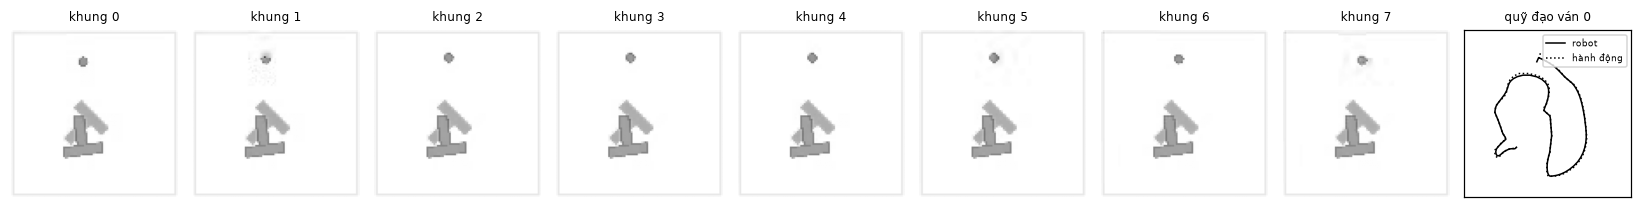

In [4]:
def read_video_frames(path, limit=None):
    """Đọc video thành mảng (số khung, 96, 96, 3). Thử OpenCV trước, nếu không đọc được AV1 thì dùng PyAV."""
    frames = []
    try:
        import cv2
        cap = cv2.VideoCapture(path)
        while cap.isOpened() and (limit is None or len(frames) < limit):
            ok, f = cap.read()
            if not ok:
                break
            frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        cap.release()
    except Exception as e:
        print("OpenCV lỗi:", e)
    if not frames:
        import av
        c = av.open(path)
        for fr in c.decode(video=0):
            frames.append(fr.to_ndarray(format="rgb24"))
            if limit is not None and len(frames) >= limit:
                break
        c.close()
    return np.stack(frames)

first = read_video_frames(VIDEO, limit=8)
print("Đọc được %d khung đầu, kích thước một khung: %s" % (len(first), first[0].shape))

fig, axs = plt.subplots(1, 9, figsize=(15, 2.0))
for i, ax in enumerate(axs[:8]):
    ax.imshow(first[i].mean(-1), cmap="gray", vmin=0, vmax=255); ax.set_title("khung %d" % i, fontsize=8); ax.axis("off")
m = EP_raw == 0
axs[8].plot(S_raw[m, 0], S_raw[m, 1], "k-", lw=1, label="robot"); axs[8].plot(A_raw[m, 0], A_raw[m, 1], "k:", lw=1, label="hành động")
axs[8].set_xlim(0, 512); axs[8].set_ylim(512, 0); axs[8].set_aspect("equal"); axs[8].set_title("quỹ đạo ván 0", fontsize=8)
axs[8].legend(fontsize=6); axs[8].set_xticks([]); axs[8].set_yticks([])
fig.tight_layout(); fig.savefig(os.path.join(RES, "b1_du_lieu.png"), dpi=150); plt.show()

**Nhận xét Bước 1.**
- Dữ liệu có đủ vị trí robot và hành động, nhưng **thiếu tư thế khối T**. Đây là lý do cần Bước 2.
- Hành động gần vị trí robot **ở khung kế tiếp** hơn khung hiện tại: robot không "nhảy" tới đích ngay mà đuổi theo mục tiêu, giống một lò xo kéo từ từ. Điều này sẽ được dùng ở Bước 5 để mô hình hóa chuyển động của robot (hệ số bám α).
- Ảnh 96×96 rất nhỏ, nên tư thế khối T ước lượng được sẽ có sai số nhỏ (đo ở Bước 2).

## 2. Mô phỏng (gym-pusht) và ước lượng tư thế khối T từ ảnh

### 2.1 Môi trường mô phỏng

Ta dùng `gym-pusht`, bản mô phỏng vật lý của đúng bài Push-T. Những điều cần biết:

| Thứ | Giá trị |
|---|---|
| Bàn | vuông 512×512; robot (hình tròn) được điều khiển bằng vị trí mục tiêu, thân robot bám theo mục tiêu như lò xo có giảm chấn (PD, kp = 100, kv = 20) |
| Tần số điều khiển | 10 Hz (mỗi bước = 0,1 giây) |
| Hình đích | khối T đặt tại (256, 256), xoay 45° (π/4) |
| Độ phủ (coverage) | diện tích khối T chồng lên hình đích, chia cho diện tích hình đích |
| Thành công | độ phủ vượt 0,95 (tại bất kỳ lúc nào trong ván) |
| Trạng thái (`obs_type="state"`) | `[robot x, robot y, khối x, khối y, góc khối]` |

Simulator đóng hai vai trò: (a) cho ta **đáp án thật** để kiểm tra việc ước lượng tư thế từ ảnh, (b) là nơi **đánh giá** mọi mô hình ở Bước 5.

Trạng thái ban đầu [robot x, robot y, khối x, khối y, góc khối]: [390.   304.   241.54 268.52   3.4 ]


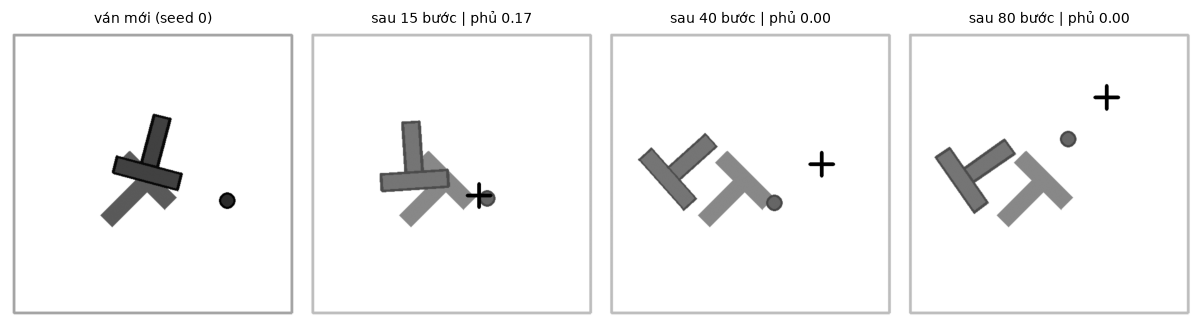

In [5]:
import gymnasium as gym
import gym_pusht  # noqa: F401  (đăng ký môi trường)

env_demo = gym.make("gym_pusht/PushT-v0", obs_type="state", render_mode="rgb_array")
obs, info = env_demo.reset(seed=0)
print("Trạng thái ban đầu [robot x, robot y, khối x, khối y, góc khối]:", np.round(obs, 2))
fig, axs = plt.subplots(1, 4, figsize=(11, 2.9))
axs[0].imshow(env_demo.render().mean(-1), cmap="gray"); axs[0].set_title("ván mới (seed 0)", fontsize=9); axs[0].axis("off")
rng_demo = np.random.default_rng(0)
for k, n_step in enumerate((15, 40, 80)):
    for _ in range(n_step - (0 if k == 0 else (15, 40)[k - 1])):
        obs, r, term, trunc, info = env_demo.step(rng_demo.uniform(100, 400, 2).astype(np.float32))   # hành động ngẫu nhiên
    axs[k + 1].imshow(env_demo.render().mean(-1), cmap="gray"); axs[k + 1].axis("off")
    axs[k + 1].set_title("sau %d bước | phủ %.2f" % (n_step, info["coverage"]), fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(RES, "b2_simulator.png"), dpi=150); plt.show()
env_demo.close()

### 2.2 Ước lượng tư thế khối T từ ảnh 96×96

**Ý tưởng (giống việc dùng một tấm khuôn):** ta biết hình dạng chữ T chính xác (một thanh ngang 120×30 và một thân dọc 30×90). Với mỗi ảnh:
1. Chọn các điểm ảnh có **màu xám-xanh** của khối T (robot xanh đậm và hình đích xanh lá bị loại bằng ngưỡng màu).
2. Thử 72 góc xoay khác nhau của khuôn chữ T, đặt khuôn sao cho tâm trùng tâm vùng màu, chọn góc cho **độ chồng khớp (IoU) cao nhất**.
3. Tinh chỉnh vị trí và góc từng chút một cho đến khi IoU không tăng nữa.

Mã được ghi ra file `pusht_pose.py` cạnh notebook, vì chạy song song nhiều tiến trình trên Windows cần hàm nằm trong một file import được.

In [6]:
%%writefile pusht_pose.py
# pusht_pose.py - ước lượng tư thế (x, y, góc) khối T từ ảnh 96x96
import numpy as np
import cv2

S = 96 / 512                                                           # hệ số đổi toạ độ 0..512 sang pixel 0..96
BAR = np.array([(-60, 30), (60, 30), (60, 0), (-60, 0)], float)        # thanh ngang của chữ T
STEM = np.array([(-15, 30), (-15, 120), (15, 120), (15, 30)], float)   # thân dọc của chữ T


def block_mask(img):
    """Chọn các pixel màu xám-xanh (khối T). Robot xanh đậm và đích xanh lá bị loại bằng ngưỡng màu."""
    im = img.astype(int)
    R, G, B = im[..., 0], im[..., 1], im[..., 2]
    return ((B - R >= 15) & (B - R <= 75) & (G - R >= 5) & (G - R <= 45) & (im.mean(-1) < 205)).astype(np.float32)


def agent_centroid(img):
    """Tâm hình tròn xanh (robot), trả về toạ độ 0..512."""
    im = img.astype(int)
    ys, xs = np.nonzero(im[..., 2] - im[..., 0] > 120)
    if len(xs) < 5:
        return np.array([np.nan, np.nan])
    return np.array([xs.mean() + 0.5, ys.mean() + 0.5]) / S


def raster(x, y, th, size=96, ss=4):
    """Vẽ chữ T ở tư thế (x, y, góc) lên lưới 96x96, giá trị 0..1 (ss = siêu lấy mẫu cho viền mịn)."""
    c, s = np.cos(th), np.sin(th)
    Rm = np.array([[c, -s], [s, c]])
    m = np.zeros((size * ss, size * ss), np.uint8)
    for poly in (BAR, STEM):
        w = (poly @ Rm.T + [x, y]) * S * ss
        cv2.fillPoly(m, [np.round(w - 0.5).astype(np.int32)], 1)
    return cv2.resize(m.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)


def iou(a, b):
    return np.minimum(a, b).sum() / (np.maximum(a, b).sum() + 1e-9)


def estimate(img):
    """Trả về ((x, y, góc), độ khớp IoU). Thử 72 góc, chọn góc khớp nhất rồi tinh chỉnh từng toạ độ."""
    m = block_mask(img)
    ys, xs = np.nonzero(m)
    if len(xs) < 20:
        return np.array([np.nan] * 3), 0.0
    cx, cy = (xs.mean() + 0.5) / S, (ys.mean() + 0.5) / S
    best = (-1.0, None)
    for th in np.linspace(-np.pi, np.pi, 72, endpoint=False):
        r = raster(256, 256, th)
        yy, xx = np.nonzero(r > 0.5)
        ox, oy = (xx.mean() + 0.5) / S - 256, (yy.mean() + 0.5) / S - 256     # tâm khuôn lệch so với gốc toạ độ khối
        p0 = (cx - ox, cy - oy, th)
        sc = iou(raster(*p0), m)
        if sc > best[0]:
            best = (sc, p0)
    sc, p = best
    p = np.array(p, float)
    step = np.array([8.0, 8.0, 0.08])
    for _ in range(40):                                                         # tinh chỉnh từng toạ độ, giảm dần bước
        improved = False
        for k in range(3):
            for d in (-1, 1):
                q = p.copy()
                q[k] += d * step[k]
                s2 = iou(raster(*q), m)
                if s2 > sc:
                    sc, p, improved = s2, q, True
        if not improved:
            step *= 0.5
            if step[0] < 0.2:
                break
    p[2] = (p[2] + np.pi) % (2 * np.pi) - np.pi
    return p, sc


def work(img):
    return estimate(img)

Writing pusht_pose.py


In [7]:
sys.path.insert(0, os.getcwd())
import importlib, pusht_pose
importlib.reload(pusht_pose)
from pusht_pose import block_mask, agent_centroid, raster, iou, estimate

# ---- Kiểm tra trên simulator, nơi ta BIẾT đáp án thật ----
env_px = gym.make("gym_pusht/PushT-v0", obs_type="pixels_agent_pos", render_mode="rgb_array")
pos_err, ang_err, ious = [], [], []
for sd in range(40):
    o, _ = env_px.reset(seed=sd)
    u = env_px.unwrapped
    p, sc = estimate(o["pixels"])
    pos_err.append(np.hypot(p[0] - u.block.position.x, p[1] - u.block.position.y))
    ang_err.append(abs((p[2] - u.block.angle + np.pi) % (2 * np.pi) - np.pi))
    ious.append(sc)
env_px.close()
pos_err, ang_err = np.array(pos_err), np.degrees(np.array(ang_err))
print("Trên 40 ảnh simulator (thang 0..512): sai số vị trí trung bình %.2f, lớn nhất %.2f | sai số góc trung bình %.2f°, lớn nhất %.2f° | IoU trung bình %.3f" %
      (pos_err.mean(), pos_err.max(), ang_err.mean(), ang_err.max(), np.mean(ious)))

Trên 40 ảnh simulator (thang 0..512): sai số vị trí trung bình 1.19, lớn nhất 3.53 | sai số góc trung bình 0.72°, lớn nhất 2.61° | IoU trung bình 0.877


**Nhận xét.** Trên ảnh simulator (có đáp án thật) sai số vị trí chỉ cỡ vài đơn vị trên bàn 512, sai số góc cỡ một đến vài độ. Với một khối T dài 120 đơn vị, đó là sai số nhỏ. Tiếp theo áp dụng cho toàn bộ ảnh thật của `lerobot/pusht`.

### 2.3 Áp dụng cho toàn bộ video (khoảng 25 650 khung)

Ô này tốn 10–20 phút lần đầu (chạy song song nhiều lõi CPU), kết quả được lưu và lần sau bỏ qua. Nó cũng kiểm tra **ảnh và bảng dữ liệu có cùng thứ tự khung không** bằng cách so tâm robot trong ảnh với vị trí robot trong bảng.

In [8]:
POSE_NPY, FIT_NPY = os.path.join(SIM, "block_pose.npy"), os.path.join(SIM, "block_fit.npy")
frames_all = None
if need(POSE_NPY, "pose"):
    t0 = time.time()
    frames_all = read_video_frames(VIDEO)
    print("Số khung đọc từ video: %d | số dòng trong bảng: %d (%.0f giây)" % (len(frames_all), len(df), time.time() - t0))
    assert len(frames_all) == len(df), "Số khung ảnh không khớp bảng dữ liệu!"

    ag_img = np.stack([agent_centroid(f) for f in frames_all])                   # kiểm tra đồng bộ ảnh - bảng
    d_sync = np.linalg.norm(ag_img - S_raw, axis=1)
    print("Đồng bộ ảnh-bảng: lệch tâm robot trung bình %.2f, trung vị %.2f, lớn nhất %.2f (thang 0..512)" %
          (np.nanmean(d_sync), np.nanmedian(d_sync), np.nanmax(d_sync)))

    from multiprocessing import Pool
    t0 = time.time()
    try:
        with Pool(max(1, (os.cpu_count() or 2) - 1)) as pool:
            out = pool.map(pusht_pose.work, list(frames_all), chunksize=64)
    except Exception as e:                                                       # nếu chạy song song lỗi thì chạy tuần tự (chậm hơn)
        print("Chạy song song lỗi (%s), chuyển sang chạy tuần tự..." % e)
        out = [pusht_pose.work(f) for f in frames_all]
    pose = np.stack([o[0] for o in out]).astype(np.float32)
    fit = np.array([o[1] for o in out], np.float32)
    np.save(POSE_NPY, pose); np.save(FIT_NPY, fit)
    print("Ước lượng xong %d khung trong %.0f giây" % (len(pose), time.time() - t0))
else:
    pose, fit = np.load(POSE_NPY), np.load(FIT_NPY)
    print("Đã có kết quả lưu, bỏ qua bước chạy lại (đặt FORCE['pose'] = True để chạy lại).")

print("Độ khớp IoU: trung bình %.3f | nhỏ nhất %.3f | số khung IoU < 0,75: %d | không tìm thấy khối: %d" %
      (fit.mean(), fit.min(), (fit < 0.75).sum(), np.isnan(pose[:, 0]).sum()))

Đã có kết quả lưu, bỏ qua bước chạy lại (đặt FORCE['pose'] = True để chạy lại).
Độ khớp IoU: trung bình 0.858 | nhỏ nhất 0.610 | số khung IoU < 0,75: 16 | không tìm thấy khối: 0


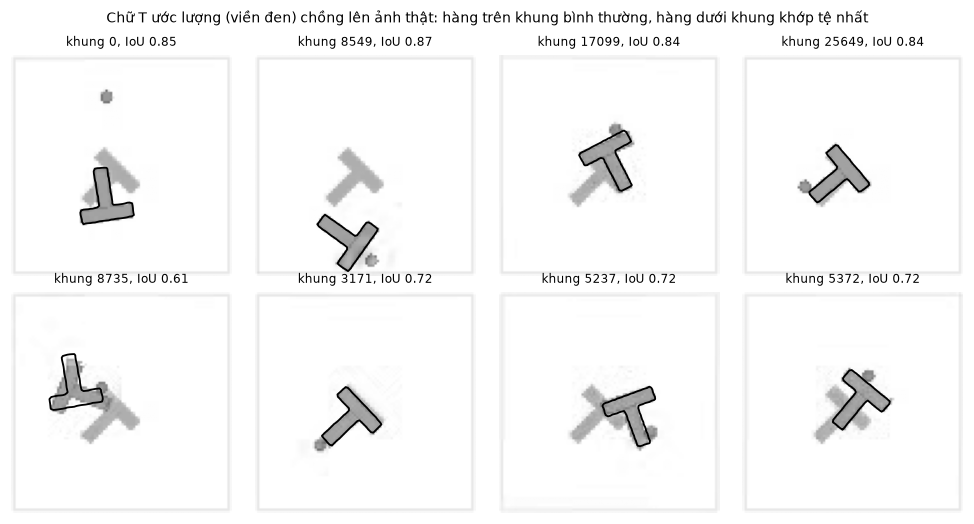

In [9]:
# Hình kiểm tra: 4 khung rải đều + 4 khung khớp tệ nhất; viền đen = chữ T ước lượng
if frames_all is None:
    frames_all = read_video_frames(VIDEO)
idx = list(np.linspace(0, len(pose) - 1, 4).astype(int)) + list(np.argsort(fit)[:4])
fig, axs = plt.subplots(2, 4, figsize=(9, 4.8))
for ax, i in zip(axs.ravel(), idx):
    ax.imshow(frames_all[i].mean(-1), cmap="gray", vmin=0, vmax=255)
    if not np.isnan(pose[i, 0]):
        ax.contour(raster(*pose[i]), levels=[0.5], colors="k", linewidths=1.2)
    ax.set_title("khung %d, IoU %.2f" % (i, fit[i]), fontsize=8); ax.axis("off")
fig.suptitle("Chữ T ước lượng (viền đen) chồng lên ảnh thật: hàng trên khung bình thường, hàng dưới khung khớp tệ nhất", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(RES, "b2_kiemtra_tuthe.png"), dpi=150); plt.show()

### 2.4 Làm sạch và dựng bộ dữ liệu cho World Model

Một số khung có độ khớp thấp (khối bị robot che một phần, hoặc ảnh nhòe). Nếu giữ nguyên, khối T sẽ "nhảy" giữa hai khung, và World Model sẽ học nhầm những cú nhảy giả đó. Cách xử lý: khung nào có IoU < 0,75 thì **nội suy** từ các khung tốt gần nhất **trong cùng ván** (vị trí nội suy tuyến tính, góc nội suy sau khi gỡ vòng 2π).

Bộ dữ liệu cuối gồm, cho mỗi khung: vị trí robot, tư thế khối T (x, y, góc), hành động, số thứ tự ván.

In [10]:
LOWDIM = os.path.join(SIM, "pusht_lowdim.npz")
IOU_MIN = 0.75

def jump_stats(blk, ep):
    """Mức khối T dịch chuyển giữa hai khung liên tiếp (cùng ván): để phát hiện các cú nhảy giả."""
    s = ep[:-1] == ep[1:]
    dpos = np.linalg.norm(blk[1:, :2] - blk[:-1, :2], axis=1)[s]
    dang = np.degrees(np.abs((blk[1:, 2] - blk[:-1, 2] + np.pi) % (2 * np.pi) - np.pi))[s]
    return dpos, dang

if need(LOWDIM, "dataset"):
    blk = pose.astype(np.float64).copy()
    bad = (fit < IOU_MIN) | np.isnan(pose[:, 0])
    before = jump_stats(blk, EP_raw)
    n_fixed = 0
    for e in np.unique(EP_raw):
        ids = np.where(EP_raw == e)[0]
        good = ~bad[ids]
        if good.all():
            continue
        if not good.any():
            continue                                                   # ván không có khung tốt nào (hiếm): giữ nguyên
        t = np.arange(len(ids))
        ang = np.unwrap(blk[ids][good, 2])                             # gỡ vòng 2π trước khi nội suy
        blk[ids, 0] = np.interp(t, t[good], blk[ids][good, 0])
        blk[ids, 1] = np.interp(t, t[good], blk[ids][good, 1])
        blk[ids, 2] = (np.interp(t, t[good], ang) + np.pi) % (2 * np.pi) - np.pi
        n_fixed += (~good).sum()
    after = jump_stats(blk, EP_raw)
    print("Số khung được nội suy: %d / %d" % (n_fixed, len(blk)))
    print("Cú nhảy khối T giữa hai khung liên tiếp: lớn nhất trước %.1f -> sau %.1f (đơn vị 0..512) | số bước nhảy > 30: trước %d -> sau %d" %
          (before[0].max(), after[0].max(), (before[0] > 30).sum(), (after[0] > 30).sum()))
    np.savez(LOWDIM, agent=S_raw, block=blk.astype(np.float32), action=A_raw, episode=EP_raw, fit=fit)
    print("Đã lưu:", LOWDIM)
else:
    print("Đã có bộ dữ liệu, bỏ qua (đặt FORCE['dataset'] = True để dựng lại).")

dd = np.load(LOWDIM)
agent_all, block_all, action_all, ep_all = dd["agent"].astype(np.float64), dd["block"].astype(np.float64), dd["action"].astype(np.float64), dd["episode"]
print("Bộ dữ liệu: %d khung, %d ván | khối T x∈[%.0f, %.0f], y∈[%.0f, %.0f]" %
      (len(ep_all), len(np.unique(ep_all)), block_all[:, 0].min(), block_all[:, 0].max(), block_all[:, 1].min(), block_all[:, 1].max()))

Đã có bộ dữ liệu, bỏ qua (đặt FORCE['dataset'] = True để dựng lại).
Bộ dữ liệu: 25650 khung, 206 ván | khối T x∈[59, 442], y∈[108, 485]


### 2.5 (Tùy chọn) Kiểm chứng tư thế ước lượng bằng bộ `lerobot/pusht_keypoints`

Cùng tập 25 650 khung, bộ `lerobot/pusht_keypoints` lưu sẵn **8 điểm góc của khối T** (suy ra được tư thế thật). Ta tải bộ nhỏ này (khoảng 2 MB, không có video), kiểm tra hai bộ có cùng thứ tự khung (so vị trí robot), rồi so tư thế **ước lượng của ta** với tư thế **suy ra từ điểm góc**. Ô này cần mạng; nếu không có mạng nó tự bỏ qua.

[Đồng bộ] lệch vị trí robot giữa hai bộ: trung bình 0.0000, lớn nhất 0.0000
[So với tư thế thật] 25650/25650 khung ghép điểm được
Sai số vị trí: trung bình 1.73 | trung vị 1.54 | p95 3.69 | lớn nhất 10.66 (thang 0..512)
Sai số góc:    trung bình 0.84° | trung vị 0.69° | p95 2.14° | lớn nhất 7.06°


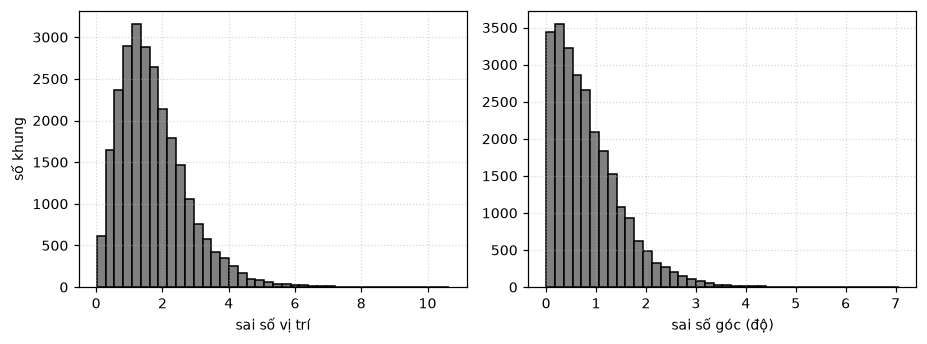

In [11]:
RUN_VERIFY = True
KP_DIR = os.path.join(RAW, "..", "raw_keypoints")
if RUN_VERIFY:
    try:
        if not glob.glob(os.path.join(KP_DIR, "**", "*.parquet"), recursive=True):
            from huggingface_hub import snapshot_download
            snapshot_download("lerobot/pusht_keypoints", repo_type="dataset", local_dir=KP_DIR, allow_patterns=["*.parquet", "*.json"])
        dfk = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob(os.path.join(KP_DIR, "data", "**", "*.parquet"), recursive=True))], ignore_index=True)
        if "index" in dfk.columns:
            dfk = dfk.sort_values("index").reset_index(drop=True)
        KPT = np.stack(dfk["observation.environment_state"].to_numpy()).astype(np.float64)
        AG_KP = np.stack(dfk["observation.state"].to_numpy()).astype(np.float64)
        n = min(len(agent_all), len(KPT))
        sync = np.abs(agent_all[:n] - AG_KP[:n])
        print("[Đồng bộ] lệch vị trí robot giữa hai bộ: trung bình %.4f, lớn nhất %.4f" % (sync.mean(), sync.max()))
        if KPT.max() <= 1.5 and KPT.min() >= 0:
            KPT = KPT * 512
        Kp = KPT[:n].reshape(n, 8, 2)
        V = np.array([(-60, 30), (60, 30), (60, 0), (-60, 0), (-15, 30), (-15, 120), (15, 120), (15, 30)], float)   # 8 đỉnh trong hệ toạ độ khối

        def world(p):
            c, s = np.cos(p[2]), np.sin(p[2])
            return V @ np.array([[c, -s], [s, c]]).T + p[:2]

        def kabsch(src, dst):
            """Phép quay + tịnh tiến biến src thành dst (theo thứ tự điểm tương ứng): trả về (x, y, góc) gốc toạ độ khối."""
            cs, cd = src.mean(0), dst.mean(0)
            U, _, Vt = np.linalg.svd((src - cs).T @ (dst - cd))
            R = Vt.T @ U.T
            if np.linalg.det(R) < 0:
                Vt[-1] *= -1; R = Vt.T @ U.T
            t = cd - R @ cs
            return np.array([t[0], t[1], np.arctan2(R[1, 0], R[0, 0])])

        pe, ae = [], []
        for i in range(n):
            P = world(block_all[i])
            match = np.linalg.norm(P[:, None, :] - Kp[i][None], axis=2).argmin(1)   # mỗi đỉnh của ta ghép với điểm gốc gần nhất
            if len(set(match)) < 8:
                pe.append(np.nan); ae.append(np.nan); continue
            tr = kabsch(V, Kp[i][match])
            pe.append(np.linalg.norm(tr[:2] - block_all[i, :2]))
            ae.append(abs((tr[2] - block_all[i, 2] + np.pi) % (2 * np.pi) - np.pi))
        pe, ae = np.array(pe), np.degrees(np.array(ae)); ok = ~np.isnan(pe)
        print("[So với tư thế thật] %d/%d khung ghép điểm được" % (ok.sum(), n))
        print("Sai số vị trí: trung bình %.2f | trung vị %.2f | p95 %.2f | lớn nhất %.2f (thang 0..512)" % (pe[ok].mean(), np.median(pe[ok]), np.percentile(pe[ok], 95), pe[ok].max()))
        print("Sai số góc:    trung bình %.2f° | trung vị %.2f° | p95 %.2f° | lớn nhất %.2f°" % (ae[ok].mean(), np.median(ae[ok]), np.percentile(ae[ok], 95), ae[ok].max()))
        fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.2))
        axs[0].hist(pe[ok], bins=40, color="0.5", edgecolor="k"); axs[0].set_xlabel("sai số vị trí"); axs[0].set_ylabel("số khung")
        axs[1].hist(ae[ok], bins=40, color="0.5", edgecolor="k"); axs[1].set_xlabel("sai số góc (độ)")
        fig.tight_layout(); fig.savefig(os.path.join(RES, "b2_kiemchung_tuthe.png"), dpi=150); plt.show()
    except Exception as e:
        print("Bỏ qua kiểm chứng (cần mạng và thư viện huggingface_hub):", repr(e)[:200])

**Nhận xét Bước 2.**
- `lerobot/pusht` bắt nguồn từ bộ dữ liệu gốc của bài Diffusion Policy (có đủ tư thế khối T) nhưng **đã bỏ cột tư thế khối T**, chỉ để lại ảnh và vị trí robot. Vì vậy ước lượng tư thế từ ảnh là cần thiết khi dùng đúng bộ này.
- Ước lượng từ ảnh cho sai số nhỏ (kiểm tra ở ô 2.2 trên simulator và ô 2.5 trên dữ liệu thật). Sai số này nhỏ hơn đáng kể so với mức khối T dịch chuyển trong một bước khi bị đẩy, nên đủ để học quy luật đẩy.
- Nội suy các khung khớp tệ giúp loại các cú nhảy giả; số khung bị sửa chiếm tỉ lệ nhỏ.
- **Hạn chế cần nói rõ:** tư thế ở đây là *ước lượng*, không phải giá trị gốc của dữ liệu. Câu hỏi "ước lượng từ ảnh có được chấp nhận không, hay phải dùng bộ gốc có sẵn tư thế" cần xác nhận với thầy.

## 3. Huấn luyện World Model (vòng 0)

**World Model làm gì?** Cho biết *robot đang ở đâu, khối T đang ở tư thế nào, và robot sắp ra lệnh gì*, mô hình đoán **khối T sẽ dịch chuyển bao nhiêu** ở khung kế tiếp. Nói đơn giản: nó học "đẩy thế này thì khối T trượt và xoay thế kia".

| | |
|---|---|
| Đầu vào (14 số) | vị trí robot, tư thế khối T (x, y, cos góc, sin góc), hành động, (hành động − robot), và vị trí robot/hành động **nhìn từ hệ toạ độ gắn với khối T** |
| Đầu ra (3 số) | mức thay đổi của khối T: Δx, Δy, Δgóc |
| Mạng | MLP 3 lớp ẩn, mỗi lớp 256 nơ-ron (ReLU) |
| Chia dữ liệu | **theo ván** (80% / 10% / 10%), để mô hình không được "xem trước" ván nào của tập kiểm tra |
| Mốc so sánh | "khối T đứng yên" (không dự đoán gì cả): mô hình phải thắng mốc này mới có giá trị |

**Vì sao thêm toạ độ "nhìn từ khối T"?** Cùng một cú đẩy, kết quả phụ thuộc robot chạm vào **mặt nào, phía nào** của khối T, chứ không phụ thuộc toạ độ trên bàn. Đưa sẵn góc nhìn này vào giúp mạng học dễ hơn.

Mã dưới đây viết thành hàm để dùng lại ở vòng lặp (Bước 5).

In [12]:
WM_H = 8                                           # số bước dự đoán nối tiếp khi kiểm tra "đoán xa"

def wrap(a):
    """Đưa góc về khoảng [-π, π)."""
    return (a + np.pi) % (2 * np.pi) - np.pi

def wm_features(ag, bl, ac):
    """Ghép đầu vào 14 số (numpy). ag: robot (N,2); bl: khối T (N,3) = x, y, góc; ac: hành động (N,2)."""
    c, s_ = np.cos(bl[:, 2]), np.sin(bl[:, 2])
    def local(v):                                  # vector (v - tâm khối T) viết trong hệ toạ độ quay theo khối T
        dx, dy = v[:, 0] - bl[:, 0], v[:, 1] - bl[:, 1]
        return np.stack([c * dx + s_ * dy, -s_ * dx + c * dy], axis=1) / 128
    return np.concatenate([ag / 512, bl[:, :2] / 512, np.cos(bl[:, 2:3]), np.sin(bl[:, 2:3]),
                           ac / 512, (ac - ag) / 128, local(ag), local(ac)], axis=1).astype(np.float32)

def make_wm():
    return nn.Sequential(nn.Linear(14, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(),
                         nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 3))

def wm_arrays(files):
    """Đọc và ghép các file dữ liệu (vd. dữ liệu người + dữ liệu robot tự chơi)."""
    ds = [np.load(os.path.join(SIM, f)) for f in files]
    return (np.concatenate([x["agent"] for x in ds]).astype(np.float64), np.concatenate([x["block"] for x in ds]).astype(np.float64),
            np.concatenate([x["action"] for x in ds]).astype(np.float64), np.concatenate([x["episode"] for x in ds]))

def wm_split(ep):
    """Chia theo ván. Ván của người (mã < 1000) và ván robot tự chơi (mã >= 1000) được chia riêng, mỗi loại 80/10/10."""
    def cut(a, seed):
        a = a.copy(); np.random.default_rng(seed).shuffle(a)
        n_tr, n_va = int(0.8 * len(a)), int(0.1 * len(a))
        return a[:n_tr], a[n_tr:n_tr + n_va], a[n_tr + n_va:]
    eps = np.unique(ep)
    h, r_ = cut(eps[eps < 1000], 0), cut(eps[eps >= 1000], 1)
    return {k: np.concatenate([h[i], r_[i]]) for i, k in enumerate(("train", "val", "test"))}

def train_wm(files, tag, force_key, epochs=WM_EPOCHS):
    """Huấn luyện (hoặc nạp lại nếu đã có file models/wm{tag}.pt). Trả về dict checkpoint."""
    path = os.path.join(MOD, "wm%s.pt" % tag)
    if not need(path, force_key):
        print("Đã có %s, nạp lại (đặt FORCE['%s'] = True để huấn luyện lại)." % (os.path.basename(path), force_key))
        return torch.load(path, map_location=dev, weights_only=False)
    torch.manual_seed(0); np.random.seed(0)
    ag, bl, ac, ep = wm_arrays(files)
    split = wm_split(ep)
    print("Số ván train/val/test: %d / %d / %d" % tuple(len(v) for v in split.values()))
    idx = {k: np.where(np.isin(ep[:-1], v) & (ep[:-1] == ep[1:]))[0] for k, v in split.items()}     # các t mà t và t+1 cùng ván
    X = {k: wm_features(ag[i], bl[i], ac[i]) for k, i in idx.items()}
    Y = {k: np.stack([bl[i + 1, 0] - bl[i, 0], bl[i + 1, 1] - bl[i, 1], wrap(bl[i + 1, 2] - bl[i, 2])], 1).astype(np.float32) for k, i in idx.items()}
    y_mu, y_sd = Y["train"].mean(0), Y["train"].std(0)
    tt = {k: (torch.tensor(X[k]).to(dev), torch.tensor((Y[k] - y_mu) / y_sd).to(dev)) for k in X}
    net = make_wm().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    lossf, BS = nn.MSELoss(), 256
    tr_c, va_c, best, best_state, t0 = [], [], 1e9, None, time.time()
    for e in range(epochs):
        net.train()
        perm = torch.randperm(len(tt["train"][0]), device=dev); tot = 0
        for i in range(0, len(perm), BS):
            b = perm[i:i + BS]
            loss = lossf(net(tt["train"][0][b]), tt["train"][1][b])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        sched.step(); net.eval()
        with torch.no_grad():
            va = lossf(net(tt["val"][0]), tt["val"][1]).item()
        tr_c.append(tot / len(perm)); va_c.append(va)
        if va < best:
            best, best_state = va, {k: v.clone() for k, v in net.state_dict().items()}
        if e % 15 == 0 or e == epochs - 1:
            print("epoch %3d | loss train %.4f | val %.4f" % (e, tr_c[-1], va))
    print("Huấn luyện xong trong %.0f giây | val tốt nhất %.4f" % (time.time() - t0, best))
    ck = {"state": best_state, "y_mu": y_mu, "y_sd": y_sd, "split": split, "curves": (tr_c, va_c)}
    torch.save(ck, path)
    return ck

def wm_report(files, ck, tag):
    """Đánh giá trên tập kiểm tra: dự đoán 1 bước và đoán xa 1..8 bước (dùng hành động thật), so với mốc 'đứng yên'."""
    ag, bl, ac, ep = wm_arrays(files)
    split, N = wm_split(ep), len(ep)
    net = make_wm().to(dev); net.load_state_dict(ck["state"]); net.eval()
    y_mu, y_sd = ck["y_mu"], ck["y_sd"]

    def step_model(a_, b_, c_):
        with torch.no_grad():
            o = net(torch.tensor(wm_features(a_, b_, c_)).to(dev)).cpu().numpy() * y_sd + y_mu
        nb = b_.copy(); nb[:, 0] += o[:, 0]; nb[:, 1] += o[:, 1]; nb[:, 2] = wrap(b_[:, 2] + o[:, 2])
        return nb

    def err(p, t):
        return np.linalg.norm(p[:, :2] - t[:, :2], axis=1), np.degrees(np.abs(wrap(p[:, 2] - t[:, 2])))

    t_all = np.where(np.isin(ep[:-1], split["test"]) & (ep[:-1] == ep[1:]))[0]
    groups = [("TẤT CẢ", np.ones(len(t_all), bool)), ("CHỈ VÁN CỦA NGƯỜI", ep[t_all] < 1000), ("CHỈ VÁN ROBOT TỰ CHƠI", ep[t_all] >= 1000)]
    for gname, sel in groups:
        t = t_all[sel]
        if len(t) == 0:
            continue
        true = bl[t + 1]
        moved = np.linalg.norm(true[:, :2] - bl[t, :2], axis=1) > 2.0            # khung khối T thực sự di chuyển
        print("=== DỰ ĐOÁN 1 BƯỚC, tập kiểm tra %s (%d mẫu; %d mẫu khối T thực sự di chuyển) ===" % (gname, len(t), moved.sum()))
        for name, p in (("World Model", step_model(ag[t], bl[t], ac[t])), ("Mốc: khối T đứng yên", bl[t])):
            e_p, e_a = err(p, true)
            print("%-22s | tất cả: vị trí %.2f, góc %.2f° | khi khối di chuyển: vị trí %.2f, góc %.2f°" %
                  (name, e_p.mean(), e_a.mean(), e_p[moved].mean() if moved.any() else float("nan"), e_a[moved].mean() if moved.any() else float("nan")))
    starts = np.array([s for s in np.where(np.isin(ep, split["test"]))[0] if s + WM_H < N and ep[s] == ep[s + WM_H]])
    cur = bl[starts].copy(); r_pos, r_ang, b_pos, b_ang = [], [], [], []
    for k in range(WM_H):
        cur = step_model(ag[starts + k], cur, ac[starts + k])
        p, a = err(cur, bl[starts + k + 1]); r_pos.append(p.mean()); r_ang.append(a.mean())
        p, a = err(bl[starts], bl[starts + k + 1]); b_pos.append(p.mean()); b_ang.append(a.mean())
    print("\n=== ĐOÁN XA 1..%d BƯỚC (sai số trung bình) ===" % WM_H)
    print("bước         :", " ".join("%6d" % (k + 1) for k in range(WM_H)))
    print("WM vị trí    :", " ".join("%6.1f" % v for v in r_pos)); print("Đứng yên     :", " ".join("%6.1f" % v for v in b_pos))
    print("WM góc (độ)  :", " ".join("%6.1f" % v for v in r_ang)); print("Đứng yên     :", " ".join("%6.1f" % v for v in b_ang))

    cur_ = ck.get("curves")
    fig, axs = plt.subplots(1, 3 if cur_ else 2, figsize=(13 if cur_ else 9, 3.6)); axs = np.atleast_1d(axs); j = 0
    if cur_:
        axs[0].plot(cur_[0], "k-", label="train"); axs[0].plot(cur_[1], "k--", label="val")
        axs[0].set_yscale("log"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("MSE (đã chuẩn hóa)"); axs[0].legend(); axs[0].set_title("Đường cong huấn luyện"); j = 1
    ks = np.arange(1, WM_H + 1)
    axs[j].plot(ks, r_pos, "k-o", label="World Model"); axs[j].plot(ks, b_pos, "k--s", label="khối T đứng yên")
    axs[j].set_xlabel("số bước dự đoán"); axs[j].set_ylabel("sai số vị trí"); axs[j].legend(); axs[j].set_title("Sai số vị trí")
    axs[j + 1].plot(ks, r_ang, "k-o", label="World Model"); axs[j + 1].plot(ks, b_ang, "k--s", label="khối T đứng yên")
    axs[j + 1].set_xlabel("số bước dự đoán"); axs[j + 1].set_ylabel("sai số góc (độ)"); axs[j + 1].legend(); axs[j + 1].set_title("Sai số góc")
    fig.tight_layout(); fig.savefig(os.path.join(RES, "b3_wm_ketqua%s.png" % tag), dpi=150); plt.show()
    return {"r_pos": r_pos, "b_pos": b_pos, "r_ang": r_ang, "b_ang": b_ang}

Đã có wm.pt, nạp lại (đặt FORCE['wm'] = True để huấn luyện lại).
=== DỰ ĐOÁN 1 BƯỚC, tập kiểm tra TẤT CẢ (2685 mẫu; 1036 mẫu khối T thực sự di chuyển) ===
World Model            | tất cả: vị trí 1.52, góc 0.87° | khi khối di chuyển: vị trí 2.28, góc 1.29°
Mốc: khối T đứng yên   | tất cả: vị trí 2.43, góc 1.37° | khi khối di chuyển: vị trí 4.84, góc 2.42°
=== DỰ ĐOÁN 1 BƯỚC, tập kiểm tra CHỈ VÁN CỦA NGƯỜI (2685 mẫu; 1036 mẫu khối T thực sự di chuyển) ===
World Model            | tất cả: vị trí 1.52, góc 0.87° | khi khối di chuyển: vị trí 2.28, góc 1.29°
Mốc: khối T đứng yên   | tất cả: vị trí 2.43, góc 1.37° | khi khối di chuyển: vị trí 4.84, góc 2.42°

=== ĐOÁN XA 1..8 BƯỚC (sai số trung bình) ===
bước         :      1      2      3      4      5      6      7      8
WM vị trí    :    1.5    1.7    1.9    2.1    2.3    2.5    2.6    2.8
Đứng yên     :    2.4    3.9    5.5    7.0    8.6   10.2   11.8   13.4
WM góc (độ)  :    0.9    1.0    1.1    1.1    1.2    1.3    1.5    1.5
Đứng yên 

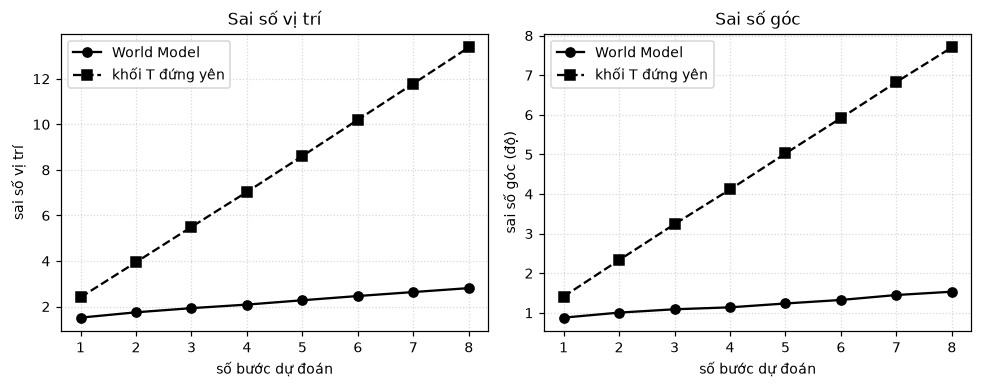

In [13]:
# World Model vòng 0: chỉ dùng dữ liệu của người
wm0 = train_wm(["pusht_lowdim.npz"], "", "wm")
rep0 = wm_report(["pusht_lowdim.npz"], wm0, "")

**Nhận xét Bước 3 (kết quả tham chiếu từ lần chạy của tác giả).**
- Dự đoán 1 bước: sai số vị trí khoảng **1,5** (mốc "đứng yên": 2,4), sai số góc khoảng **0,9°** (mốc: 1,4°). Khi chỉ xét các khung khối T **thực sự di chuyển**: 2,3 so với 4,8.
- Đoán xa 8 bước liên tiếp (dùng hành động thật, tự nối kết quả vào đầu vào kế tiếp): World Model chỉ lệch **2,8** ở bước 8, trong khi mốc "đứng yên" lệch **13,4**; góc lệch 1,5° so với 7,7°. Tức là sai số của World Model tăng **rất chậm** theo số bước, còn mốc đứng yên tăng gần tuyến tính. Đây là điều quan trọng, vì Bước 5 dùng World Model để tưởng tượng 8 bước tương lai.
- Đường cong huấn luyện: loss train và val cùng giảm rồi phẳng, khoảng cách hai đường nhỏ, nên mô hình không học vẹt.
- **Giới hạn:** World Model học từ dữ liệu *người chơi*; ở những tình huống robot tự chơi mà người hiếm gặp (ví dụ bị kẹt), nó kém chắc hơn. Đó chính là lý do có vòng lặp ở Bước 5.

## 4. Huấn luyện Diffusion Policy (DiT)

### 4.1 Ý tưởng, giải thích đơn giản

Mục tiêu: cho robot **biết nên đẩy thế nào**. Mô hình học từ các ván của người, theo trò chơi **khử nhiễu** (không cần ai gán nhãn thêm, nên gọi là tự giám sát):

1. Lấy một **chuỗi 16 hành động thật** của người (đường đi tương lai của robot).
2. **Trộn nhiễu** vào chuỗi đó, mức nhiễu chọn ngẫu nhiên từ nhẹ đến rất nặng.
3. Cho mô hình xem chuỗi đã bị nhiễu, mức nhiễu, và **2 khung quan sát gần nhất** (robot, khối T); bắt nó **đoán phần nhiễu đã trộn vào**.

Khi dùng thật: bắt đầu từ chuỗi toàn nhiễu, rồi **khử nhiễu dần** (16 bước DDIM) thành một chuỗi hành động hợp lý. Vì mỗi lần bắt đầu từ nhiễu khác nhau, mô hình cho ra **nhiều chuỗi ứng viên khác nhau**: đó chính là chỗ World Model sẽ chọn lọc ở Bước 5.

### 4.2 Mô hình và siêu tham số

Dùng **DiT** (Diffusion Transformer, điều kiện hóa bằng adaLN-Zero) thay cho mạng CNN của bài báo gốc. Siêu tham số lấy theo **Bảng 8 của bài báo Diffusion Policy** (Push-T, bản Transformer):

| Tham số | Giá trị |
|---|---|
| Số khung quan sát To / độ dài chuỗi dự đoán Tp / số hành động thực hiện Ta | 2 / 16 / 8 |
| Số lớp / độ rộng / số đầu chú ý | 8 / 256 / 4 |
| Dropout chú ý | 0,01 |
| Tốc độ học / weight decay (chỉ áp lên ma trận trọng số) | 1e-4 / 0,1 |
| Khởi động / lịch giảm | 1000 bước tăng dần, rồi giảm cosine |
| Batch / số bước nhiễu huấn luyện | 256 / 100 (lịch cosine) |
| Số epoch / EMA | 300 / trung bình trượt của trọng số |

Mã mô hình dưới đây là bản của ta, viết gọn từ ý tưởng bài gốc (không dùng thư viện `diffusers`).

In [14]:
# ============ Thành phần dùng chung của Diffusion Policy (DiT) ============
T_OBS = 2        # số khung quan sát đưa vào (khung trước và khung hiện tại)
T_PRED = 16      # độ dài chuỗi hành động dự đoán
T_ACT = 8        # số hành động thực hiện trước khi lập kế hoạch lại
N_DIFF = 100     # số bước nhiễu khi huấn luyện

def obs_feat(agent, block):
    """agent (...,2) toạ độ 0..512; block (...,3) = x, y, góc. Trả về (...,6) đã chuẩn hóa."""
    return np.concatenate([(agent - 256) / 256, (block[..., :2] - 256) / 256,
                           np.cos(block[..., 2:3]), np.sin(block[..., 2:3])], axis=-1).astype(np.float32)

def norm_act(a):   return (a - 256.0) / 256.0
def denorm_act(a): return a * 256.0 + 256.0

def build_samples(agent, block, action, ep, ep_list):
    """Mỗi mẫu: quan sát ở khung t-1, t -> chuỗi hành động a_t ... a_(t+15) (lặp lại hành động cuối nếu hết ván)."""
    feats = obs_feat(agent, block)
    O, A = [], []
    for e in ep_list:
        ids = np.where(ep == e)[0]
        lo, hi = ids[0], ids[-1]
        for t in ids:
            O.append(np.concatenate([feats[max(t - 1, lo)], feats[t]]))
            A.append(np.stack([action[min(t + k, hi)] for k in range(T_PRED)]))
    return np.array(O, np.float32), norm_act(np.array(A, np.float32))

def make_schedule(n=N_DIFF, s=0.008):
    """Lịch nhiễu cosine. Trả về alpha_bar[t]: tỉ lệ 'tín hiệu còn lại' ở bước nhiễu t."""
    x = np.linspace(0, n, n + 1)
    f = np.cos(((x / n) + s) / (1 + s) * np.pi / 2) ** 2
    ab = f / f[0]
    betas = np.clip(1 - ab[1:] / ab[:-1], 0, 0.999)
    return torch.tensor(np.cumprod(1 - betas), dtype=torch.float32)

def sincos(t, dim):
    """Mã hóa số bước nhiễu thành vector (như mã hóa vị trí trong Transformer)."""
    half = dim // 2
    f = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * f[None]
    return torch.cat([a.sin(), a.cos()], dim=-1)

class Block(nn.Module):
    """Khối Transformer có điều kiện adaLN-Zero: (bước nhiễu + quan sát) điều khiển cách chuẩn hóa và độ lớn đầu ra."""
    def __init__(self, d, heads, drop=0.0):
        super().__init__()
        self.n1 = nn.LayerNorm(d, elementwise_affine=False)
        self.attn = nn.MultiheadAttention(d, heads, dropout=drop, batch_first=True)
        self.n2 = nn.LayerNorm(d, elementwise_affine=False)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.mod = nn.Linear(d, 6 * d)
        nn.init.zeros_(self.mod.weight); nn.init.zeros_(self.mod.bias)       # "Zero": lúc đầu mỗi khối là phép đồng nhất

    def forward(self, x, c):
        s1, b1, g1, s2, b2, g2 = self.mod(c).unsqueeze(1).chunk(6, dim=-1)
        h = self.n1(x) * (1 + s1) + b1
        x = x + g1 * self.attn(h, h, h, need_weights=False)[0]
        h = self.n2(x) * (1 + s2) + b2
        return x + g2 * self.mlp(h)

class DiT(nn.Module):
    """Nhận chuỗi hành động đã nhiễu (B,16,2), bước nhiễu t, quan sát (B,12); trả về nhiễu dự đoán (B,16,2)."""
    def __init__(self, d=128, depth=4, heads=4, obs_dim=T_OBS * 6, drop=0.0):
        super().__init__()
        self.d = d
        self.inp = nn.Linear(2, d)
        self.pos = nn.Parameter(torch.randn(1, T_PRED, d) * 0.02)
        self.t_mlp = nn.Sequential(nn.Linear(d, d), nn.SiLU(), nn.Linear(d, d))
        self.o_mlp = nn.Sequential(nn.Linear(obs_dim, d), nn.SiLU(), nn.Linear(d, d))
        self.blocks = nn.ModuleList([Block(d, heads, drop) for _ in range(depth)])
        self.nf = nn.LayerNorm(d, elementwise_affine=False)
        self.mod_f = nn.Linear(d, 2 * d)
        self.out = nn.Linear(d, 2)
        nn.init.zeros_(self.mod_f.weight); nn.init.zeros_(self.mod_f.bias)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)

    def forward(self, x, t, obs):
        c = self.t_mlp(sincos(t, self.d)) + self.o_mlp(obs)
        h = self.inp(x) + self.pos
        for b in self.blocks:
            h = b(h, c)
        s, b_ = self.mod_f(c).unsqueeze(1).chunk(2, dim=-1)
        return self.out(self.nf(h) * (1 + s) + b_)

@torch.no_grad()
def ddim_sample(model, obs, ab, steps=16, n_cand=1):
    """Lấy mẫu DDIM (nhanh, không ngẫu nhiên thêm). obs (B,12) -> (B*n_cand, 16, 2) trong [-1, 1]."""
    obs = obs.repeat_interleave(n_cand, dim=0)
    x = torch.randn(len(obs), T_PRED, 2, device=obs.device)
    ts = np.linspace(N_DIFF - 1, 0, steps).round().astype(int)
    for i, t in enumerate(ts):
        a_t = ab[t]
        a_p = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=obs.device)
        eps = model(x, torch.full((len(x),), int(t), device=obs.device), obs)
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()
        x = a_p.sqrt() * x0 + (1 - a_p).sqrt() * eps
    return x

@torch.no_grad()
def ddpm_sample(model, obs, ab, n_cand=1):
    """Lấy mẫu DDPM đầy đủ như code gốc của tác giả: 100 bước, có thêm nhiễu ở mỗi bước, kẹp về [-1, 1]."""
    obs = obs.repeat_interleave(n_cand, dim=0)
    x = torch.randn(len(obs), T_PRED, 2, device=obs.device)
    ab_prev = torch.cat([torch.ones(1, device=obs.device), ab[:-1]])
    for t in range(N_DIFF - 1, -1, -1):
        a_t, a_p = ab[t], ab_prev[t]
        alpha = a_t / a_p; beta = 1 - alpha
        eps = model(x, torch.full((len(x),), t, device=obs.device), obs)
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        mean = (a_p.sqrt() * beta / (1 - a_t)) * x0 + (alpha.sqrt() * (1 - a_p) / (1 - a_t)) * x
        x = mean + (beta * (1 - a_p) / (1 - a_t)).clamp(min=1e-20).sqrt() * torch.randn_like(x) if t > 0 else mean
    return x

def sample_actions(model, obs, ab, sampler="ddim", steps=16, n_cand=1):
    return ddpm_sample(model, obs, ab, n_cand=n_cand) if sampler == "ddpm" else ddim_sample(model, obs, ab, steps=steps, n_cand=n_cand)

def load_dp(path):
    """Nạp checkpoint Diffusion Policy (trọng số EMA); cấu hình mạng được lưu cùng checkpoint."""
    ck = torch.load(path, map_location=dev, weights_only=False)
    m = DiT(**ck.get("cfg", {})).to(dev)
    m.load_state_dict(ck["ema"])
    return m.eval()

ab = make_schedule().to(dev)

Đã có checkpoint cuối (dp_v2_e300.pt), bỏ qua huấn luyện (đặt FORCE['dp'] = True để huấn luyện lại).


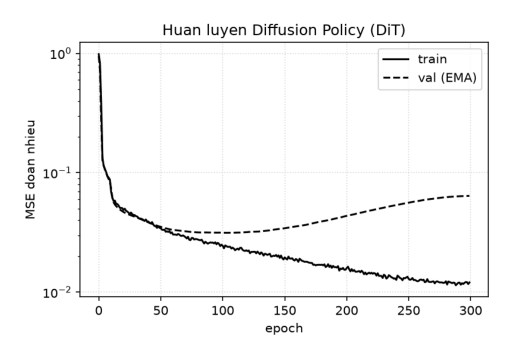

In [15]:
DP_CFG = {"d": 256, "depth": 8, "heads": 4, "drop": 0.01}      # theo Bảng 8 của bài báo (Push-T, Transformer)
DP_LR, DP_WD, DP_WARMUP, DP_BS, DP_SAVE_EVERY = 1e-4, 0.1, 1000, 256, 25

def train_dp(tag=DP_TAG, epochs=DP_EPOCHS):
    """Huấn luyện DiT; lưu checkpoint mỗi DP_SAVE_EVERY epoch (để chọn bằng simulator) và bản val tốt nhất."""
    torch.manual_seed(0); np.random.seed(0)
    eps = np.unique(ep_all); rng = np.random.default_rng(0); rng.shuffle(eps)
    n_tr, n_va = int(0.8 * len(eps)), int(0.1 * len(eps))
    split = {"train": eps[:n_tr], "val": eps[n_tr:n_tr + n_va], "test": eps[n_tr + n_va:]}
    Otr, Atr = build_samples(agent_all, block_all, action_all, ep_all, split["train"])
    Ova, Ava = build_samples(agent_all, block_all, action_all, ep_all, split["val"])
    print("Số mẫu train/val: %d / %d | quan sát %s | chuỗi hành động %s" % (len(Otr), len(Ova), Otr.shape[1:], Atr.shape[1:]))
    Otr, Atr, Ova, Ava = (torch.tensor(v).to(dev) for v in (Otr, Atr, Ova, Ava))

    model = DiT(**DP_CFG).to(dev)
    ema = copy.deepcopy(model).eval()                         # EMA: bản "trung bình trượt" của trọng số, ổn định hơn khi lấy mẫu
    print("Số tham số DiT: %.2f triệu" % (sum(p.numel() for p in model.parameters()) / 1e6))
    decay = [p for n, p in model.named_parameters() if p.ndim >= 2 and n != "pos"]
    no_decay = [p for n, p in model.named_parameters() if not (p.ndim >= 2 and n != "pos")]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": DP_WD}, {"params": no_decay, "weight_decay": 0.0}], lr=DP_LR, betas=(0.95, 0.999))
    n_it = epochs * ((len(Otr) + DP_BS - 1) // DP_BS)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: (i + 1) / DP_WARMUP if i < DP_WARMUP else 0.5 * (1 + math.cos(math.pi * (i - DP_WARMUP) / max(1, n_it - DP_WARMUP))))

    def diff_loss(m, o, a, gen=None):
        t = torch.randint(0, N_DIFF, (len(a),), device=dev, generator=gen)
        noise = torch.randn(a.shape, device=dev, generator=gen)
        x = ab[t].sqrt()[:, None, None] * a + (1 - ab[t]).sqrt()[:, None, None] * noise     # trộn nhiễu vào chuỗi hành động thật
        return nn.functional.mse_loss(m(x, t, o), noise)                                    # đoán phần nhiễu đã trộn

    tr_c, va_c, it, t0 = [], [], 0, time.time()
    best_val, best_ep, best_state = 1e9, -1, None
    for e in range(epochs):
        model.train()
        perm = torch.randperm(len(Otr), device=dev); tot = 0
        for i in range(0, len(perm), DP_BS):
            b = perm[i:i + DP_BS]
            loss = diff_loss(model, Otr[b], Atr[b])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            it += 1
            dec = min(0.999, (1 + it) / (10 + it))
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.mul_(dec).add_(pm.detach(), alpha=1 - dec)
            tot += loss.item() * len(b)
        tr_c.append(tot / len(perm))
        with torch.no_grad():
            g = torch.Generator(device=dev); g.manual_seed(0)           # nhiễu cố định -> các epoch so sánh được với nhau
            va_c.append(diff_loss(ema, Ova, Ava, g).item())
        if va_c[-1] < best_val:
            best_val, best_ep = va_c[-1], e
            best_state = {k: v.detach().clone() for k, v in ema.state_dict().items()}
        if (e + 1) % DP_SAVE_EVERY == 0:
            torch.save({"ema": {k: v.detach().clone() for k, v in ema.state_dict().items()}, "cfg": DP_CFG}, os.path.join(MOD, "dp%s_e%03d.pt" % (tag, e + 1)))
        if e % 10 == 0 or e == epochs - 1:
            print("epoch %3d | loss train %.4f | val(EMA) %.4f | %.0f giây" % (e, tr_c[-1], va_c[-1], time.time() - t0))
    print("Val thấp nhất ở epoch %d (%.4f); bản cuối %.4f" % (best_ep, best_val, va_c[-1]))
    torch.save({"ema": best_state, "cfg": DP_CFG, "split": split}, os.path.join(MOD, "dp%s.pt" % tag))
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.plot(tr_c, "k-", label="train"); ax.plot(va_c, "k--", label="val (EMA)")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE đoán nhiễu"); ax.legend(); ax.set_title("Huấn luyện Diffusion Policy (DiT)")
    fig.tight_layout(); fig.savefig(os.path.join(RES, "b4_dp_huanluyen%s.png" % tag), dpi=150); plt.show()

last_ckpt = os.path.join(MOD, "dp%s_e%03d.pt" % (DP_TAG, DP_EPOCHS))
if need(last_ckpt, "dp"):
    train_dp()
else:
    print("Đã có checkpoint cuối (%s), bỏ qua huấn luyện (đặt FORCE['dp'] = True để huấn luyện lại)." % os.path.basename(last_ckpt))
    fig_path = os.path.join(RES, "dp_huanluyen%s.png" % DP_TAG)
    if os.path.exists(fig_path):                                  # hiển thị lại đường cong của lần huấn luyện trước
        plt.figure(figsize=(6, 4)); plt.imshow(plt.imread(fig_path)); plt.axis("off"); plt.grid(False); plt.show()

### 4.3 Chọn checkpoint bằng simulator (cách làm của bài báo gốc)

Hàm mất mát trên tập val **không** phản ánh robot chơi giỏi hay dở: đường val của ta thấp nhất ở khoảng epoch 100, trong khi các checkpoint sau đó (epoch 175–225) chơi trong simulator tốt hơn. Bài báo gốc cũng chọn checkpoint bằng cách **chạy simulator** (cứ 50 epoch). Ta làm tương tự: lưu checkpoint mỗi 25 epoch, chơi thử mỗi checkpoint, chọn theo điểm.

**Hai chỉ số dùng xuyên suốt:**
- **Tỉ lệ thành công:** số ván có độ phủ vượt 0,95 tại một thời điểm nào đó.
- **Điểm kiểu bài báo:** trung bình của min(1, độ phủ tối đa / 0,95). Mềm hơn: ván phủ 90% vẫn được gần 0,95 điểm chứ không bị tính 0.

Trước hết, định nghĩa bộ chạy simulator dùng chung cho mọi cấu hình (có chỗ móc để World Model chen vào ở Bước 5).

In [16]:
def make_env(render=False):
    return gym.make("gym_pusht/PushT-v0", obs_type="state", render_mode="rgb_array" if render else None)

def feat_obs(o):
    return obs_feat(o[:2].astype(np.float64), np.array([o[2], o[3], o[4]], np.float64))

def play(seed, model, env, n_cand=1, planner=None, record=None, on_step=None, sampler="ddim"):
    """Chơi một ván. Mỗi lần lập kế hoạch: Diffusion sinh n_cand chuỗi hành động; nếu có `planner` thì nó chọn chuỗi tốt nhất,
    nếu không thì lấy chuỗi đầu tiên. Thực hiện T_ACT hành động đầu rồi lập kế hoạch lại.
    Trả về (độ phủ tối đa, thành công)."""
    torch.manual_seed(seed)
    o, _ = env.reset(seed=seed)
    hist = [feat_obs(o), feat_obs(o)]
    best, step, done = 0.0, 0, False
    info = {"is_success": False}
    while step < MAX_STEPS and not done:
        ob = torch.tensor(np.concatenate(hist)[None]).to(dev)
        act = denorm_act(sample_actions(model, ob, ab, sampler, DDIM_STEPS, n_cand=n_cand))        # (n_cand, 16, 2)
        j = planner(o, act) if (planner is not None and n_cand > 1) else 0
        for a in act[j, :T_ACT].cpu().numpy():
            a = np.clip(a, 0, 512).astype(np.float32)
            if record is not None:
                record(o, a)                                      # ghi trạng thái THẬT trước khi thực hiện hành động
            o, r, term, trunc, info = env.step(a)
            hist = [hist[1], feat_obs(o)]
            best = max(best, info["coverage"]); step += 1
            if on_step is not None:
                on_step(step, info["coverage"])
            if term or step >= MAX_STEPS:
                done = True
                break
    return best, bool(info["is_success"])

def paper_score(best_cov):
    return float(np.mean(np.minimum(np.asarray(best_cov) / 0.95, 1.0)))

In [17]:
FINAL_DP = os.path.join(MOD, "dp_final.pt")
SELECT_MIN_EPOCH = 175                                           # chỉ chấm checkpoint từ epoch này trở đi (các epoch đầu chắc chắn chưa đủ)
SELECT_JSON = os.path.join(RES, "chon_checkpoint%s.json" % DP_TAG)

if need(FINAL_DP, "select"):
    files = [f for f in sorted(glob.glob(os.path.join(MOD, "dp%s_e*.pt" % DP_TAG))) if int(re.search(r"_e(\d+)\.pt$", f).group(1)) >= SELECT_MIN_EPOCH]
    env_sel = make_env()
    rows = []
    for f in files:
        t0 = time.time(); m = load_dp(f)
        r = np.array([play(SEED_SELECT + i, m, env_sel) for i in range(N_SELECT)], float)
        rows.append({"file": os.path.basename(f), "success": float(r[:, 1].mean()), "cov": float(r[:, 0].mean()), "score": paper_score(r[:, 0])})
        print("%-16s | thành công %3.0f%% | phủ TB %.2f | điểm bài báo %.3f | %.0f giây" % (rows[-1]["file"], 100 * rows[-1]["success"], rows[-1]["cov"], rows[-1]["score"], time.time() - t0))
    json.dump(rows, open(SELECT_JSON, "w"), indent=1)
    b = max(rows, key=lambda x: (round(x["score"], 3), x["success"]))
    import shutil; shutil.copy(os.path.join(MOD, b["file"]), FINAL_DP)
    print("\nChọn %s (điểm cao nhất) làm dp_final.pt" % b["file"])
else:
    print("Đã có dp_final.pt, bỏ qua bước chọn checkpoint (đặt FORCE['select'] = True để chọn lại).")
    if os.path.exists(SELECT_JSON):
        for r in json.load(open(SELECT_JSON)):
            print("%-16s | thành công %3.0f%% | phủ TB %.2f | điểm bài báo %.3f" % (r["file"], 100 * r["success"], r["cov"], r["score"]))
dp_final = load_dp(FINAL_DP)

Đã có dp_final.pt, bỏ qua bước chọn checkpoint (đặt FORCE['select'] = True để chọn lại).


**Kết quả chọn checkpoint (lần chạy tham chiếu, 50 ván mỗi checkpoint, seed 2000–2049):**

| Checkpoint | Thành công | Phủ TB | Điểm bài báo |
|---|---|---|---|
| e175 | 66% | 0,91 | 0,951 |
| e200 | 52% | 0,91 | 0,955 |
| e225 | 62% | 0,91 | 0,954 |
| e250 | 56% | 0,88 | 0,923 |
| e275 | 62% | 0,88 | 0,921 |
| e300 | 58% | 0,88 | 0,916 |

**Nhận xét Bước 4.**
- Ba checkpoint e175, e200, e225 **ngang nhau** (điểm 0,951–0,955 chênh dưới 0,005, trong khi sai số của tỉ lệ thành công trên 50 ván khoảng ±7%). Ba checkpoint cuối (e250–e300) **kém hơn thật**: điểm rơi xuống khoảng 0,92. Học quá lâu làm mô hình bám sát dữ liệu huấn luyện và chơi tệ đi.
- Ta chốt **e225** (thành công 62% và điểm 0,954, tốt đều ở cả hai chỉ số) làm `dp_final.pt`. Công cụ chấm tự động sẽ chọn e200 vì điểm nhỉnh hơn 0,001; sự khác biệt này không có ý nghĩa thống kê.
- Vì checkpoint được chọn dựa trên chính các ván seed 2000–2049, điểm ở bảng này **hơi lạc quan**. Các con số dùng để kết luận ở Bước 5 được đo trên seed hoàn toàn mới (4000 trở đi).
- Cấu hình theo bài báo (8 lớp, độ rộng 256, dropout 0,01, weight decay 0,1) cho kết quả tốt hơn hẳn cấu hình nhỏ ban đầu của ta; đạt mức tương đương số liệu bài báo gốc cho Push-T (điểm khoảng 0,91–0,95).

## 5. Đánh giá, vòng lặp và clip minh họa

### 5.1 World Model chen vào Diffusion như thế nào?

Mỗi lần lập kế hoạch (cứ 8 bước một lần):

1. Diffusion sinh **K = 16 chuỗi hành động ứng viên** (mỗi chuỗi dài 16).
2. Với từng ứng viên, World Model **tưởng tượng 8 bước đầu**: robot làm hành động đó thì khối T đi đâu? (Robot được mô hình hóa là bám hành động theo công thức `s_(t+1) = s_t + α (a_t − s_t)`, hệ số α ước lượng từ dữ liệu.)
3. Chấm **chi phí** = khoảng cách từ khối T tưởng tượng tới đích + 60 × (độ lệch góc, đơn vị rad). Hệ số 60 vì lệch 1 rad cỡ nửa chiều dài khối T.
4. Chọn ứng viên có chi phí **nhỏ nhất**, thực hiện 8 hành động đầu, rồi lập kế hoạch lại.

Vì sao thiết kế này hợp lý: Diffusion đảm bảo các ứng viên **giống cách người chơi** (không làm điều kỳ quặc), còn World Model chỉ phải **xếp hạng**, việc dễ hơn nhiều so với tự nghĩ ra hành động.

In [18]:
GOAL = torch.tensor([256.0, 256.0, np.pi / 4], device=dev)     # tư thế đích của khối T
ANGLE_W = 60.0                                                  # 1 rad lệch góc ~ 60 đơn vị khoảng cách

# ---- Robot bám hành động chậm thế nào? s_(t+1) - s_t = α (a_t - s_t): ước lượng α bằng bình phương tối thiểu từ dữ liệu ----
same_ep = ep_all[:-1] == ep_all[1:]
dx, dv = (action_all[:-1] - agent_all[:-1])[same_ep], (agent_all[1:] - agent_all[:-1])[same_ep]
ALPHA = float((dx * dv).sum() / (dx * dx).sum())
print("Hệ số robot bám hành động α = %.2f (mỗi bước robot đi được khoảng %.0f%% quãng đường tới điểm đặt)" % (ALPHA, 100 * ALPHA))

def wm_feat_t(ag, bl, ac):
    """Giống hệt wm_features nhưng bằng torch (chạy trên GPU, cho nhiều ứng viên cùng lúc)."""
    c, s = torch.cos(bl[:, 2]), torch.sin(bl[:, 2])
    def local(v):
        x, y = v[:, 0] - bl[:, 0], v[:, 1] - bl[:, 1]
        return torch.stack([c * x + s * y, -s * x + c * y], 1) / 128
    return torch.cat([ag / 512, bl[:, :2] / 512, c[:, None], s[:, None], ac / 512, (ac - ag) / 128, local(ag), local(ac)], 1)

# Kiểm tra hai cách viết cho cùng kết quả (nếu lệch, World Model sẽ nhận sai đầu vào khi lập kế hoạch)
_r = np.random.default_rng(1)
_ag, _ac, _bl = _r.uniform(0, 512, (50, 2)), _r.uniform(0, 512, (50, 2)), np.c_[_r.uniform(0, 512, (50, 2)), _r.uniform(-np.pi, np.pi, 50)]
_d = np.abs(wm_features(_ag, _bl, _ac) - wm_feat_t(*(torch.tensor(v, dtype=torch.float32) for v in (_ag, _bl, _ac))).numpy()).max()
print("Kiểm tra đặc trưng numpy so với torch: lệch lớn nhất %.2e" % _d); assert _d < 1e-4

def load_wm(path):
    ck = torch.load(path, map_location=dev, weights_only=False)
    net = make_wm().to(dev); net.load_state_dict(ck["state"]); net.eval()
    return net, torch.tensor(ck["y_mu"], device=dev), torch.tensor(ck["y_sd"], device=dev)

@torch.no_grad()
def wm_imagine(pack, ag0, bl0, act):
    """World Model tưởng tượng T_ACT bước đầu của mỗi chuỗi ứng viên. act (K,16,2) đơn vị 0..512. Trả về tư thế khối T cuối cùng (K,3)."""
    net, y_mu, y_sd = pack
    n = len(act)
    ag, bl = ag0.expand(n, 2).clone(), bl0.expand(n, 3).clone()
    for k in range(T_ACT):
        ac = act[:, k]
        o = net(wm_feat_t(ag, bl, ac)) * y_sd + y_mu
        bl = torch.stack([bl[:, 0] + o[:, 0], bl[:, 1] + o[:, 1], bl[:, 2] + o[:, 2]], 1)
        ag = ag + ALPHA * (ac - ag)                                   # robot bám theo hành động
    return bl

def plan_cost(bl):
    dist = (bl[:, :2] - GOAL[:2]).norm(dim=1)
    dang = torch.remainder(bl[:, 2] - GOAL[2] + np.pi, 2 * np.pi) - np.pi
    return dist + ANGLE_W * dang.abs()

def make_planner(pack):
    def planner(o, act):
        ag0 = torch.tensor(o[:2], dtype=torch.float32, device=dev)[None]
        bl0 = torch.tensor([o[2], o[3], o[4]], dtype=torch.float32, device=dev)[None]
        return int(plan_cost(wm_imagine(pack, ag0, bl0, act)).argmin())
    return planner

wm0_pack = load_wm(os.path.join(MOD, "wm.pt"))

Hệ số robot bám hành động α = 0.40 (mỗi bước robot đi được khoảng 40% quãng đường tới điểm đặt)
Kiểm tra đặc trưng numpy so với torch: lệch lớn nhất 4.77e-07


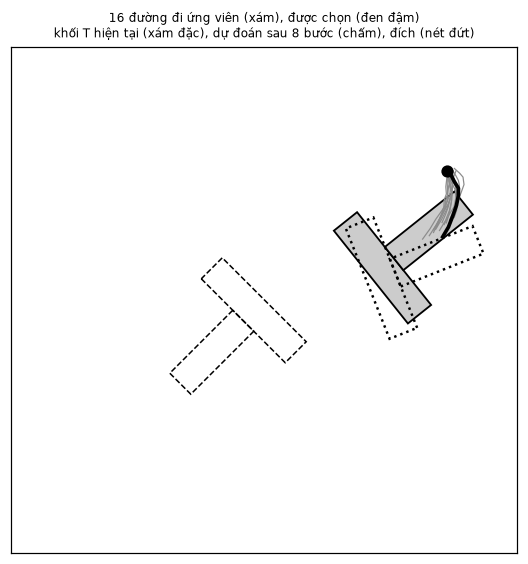

In [19]:
# Hình minh họa một lần lập kế hoạch: 16 ứng viên Diffusion sinh ra, World Model chọn ứng viên nào?
from pusht_pose import BAR, STEM
def t_polys(x, y, th):
    c, s = np.cos(th), np.sin(th)
    return [p @ np.array([[c, -s], [s, c]]).T + [x, y] for p in (BAR, STEM)]

env_v = make_env(); o, _ = env_v.reset(seed=SEED_EVAL + 3)
for _ in range(3):                                          # chơi vài bước đầu để khối T bắt đầu dịch chuyển
    torch.manual_seed(1)
    ob = torch.tensor(np.concatenate([feat_obs(o)] * 2)[None]).to(dev)
    a0 = denorm_act(sample_actions(dp_final, ob, ab, "ddim", DDIM_STEPS))[0, :T_ACT].cpu().numpy()
    for a in a0:
        o, *_ = env_v.step(np.clip(a, 0, 512).astype(np.float32))
torch.manual_seed(2)
ob = torch.tensor(np.concatenate([feat_obs(o)] * 2)[None]).to(dev)
cand = denorm_act(sample_actions(dp_final, ob, ab, "ddim", DDIM_STEPS, n_cand=K))
ag0 = torch.tensor(o[:2], dtype=torch.float32, device=dev)[None]; bl0 = torch.tensor([o[2], o[3], o[4]], dtype=torch.float32, device=dev)[None]
bl_end = wm_imagine(wm0_pack, ag0, bl0, cand); cost = plan_cost(bl_end); jbest = int(cost.argmin())

fig, ax = plt.subplots(figsize=(5.2, 5.2))
for poly in t_polys(256, 256, np.pi / 4):
    ax.fill(poly[:, 0], poly[:, 1], facecolor="none", edgecolor="k", ls="--", lw=1.0)
for poly in t_polys(*bl0[0].cpu().numpy()):
    ax.fill(poly[:, 0], poly[:, 1], facecolor="0.8", edgecolor="k", lw=1.2)
for poly in t_polys(*bl_end[jbest].cpu().numpy()):
    ax.fill(poly[:, 0], poly[:, 1], facecolor="none", edgecolor="k", ls=":", lw=1.6)
cp = cand.cpu().numpy()
for j in range(K):
    ax.plot(cp[j, :T_ACT, 0], cp[j, :T_ACT, 1], "-", color="0.55", lw=0.8)
ax.plot(cp[jbest, :T_ACT, 0], cp[jbest, :T_ACT, 1], "k-", lw=2.4)
ax.plot(o[0], o[1], "ko", ms=7)
ax.set_xlim(0, 512); ax.set_ylim(512, 0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("16 đường đi ứng viên (xám), được chọn (đen đậm)\nkhối T hiện tại (xám đặc), dự đoán sau 8 bước (chấm), đích (nét đứt)", fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(RES, "b5_chon_ungvien.png"), dpi=150); plt.show(); env_v.close()

### 5.2 Đánh giá: Chỉ Diffusion và Diffusion + World Model (vòng 0)

Mỗi cấu hình chơi **cùng N_EVAL ván trên cùng các seed** (seed là con số quyết định vị trí xuất phát ngẫu nhiên: cùng seed thì cùng thế cờ ban đầu), nên so sánh theo từng ván được. Dùng seed **4000 trở đi**, hoàn toàn mới so với các seed đã dùng để chọn checkpoint.

Kết quả được lưu vào file `.json` theo từng cấu hình, lần chạy sau đọc lại.

In [20]:
def evaluate(name, wm_path=None, seed0=SEED_EVAL, n=N_EVAL):
    """Chơi n ván (seed0 ... seed0+n-1). wm_path=None: chỉ Diffusion; có wm_path: Diffusion + World Model (K ứng viên)."""
    path = os.path.join(RES, "danhgia_%s_s%d_n%d.json" % (name, seed0, n))
    if need(path, "eval"):
        env_e = make_env()
        planner = make_planner(load_wm(wm_path)) if wm_path else None
        t0, best, succ = time.time(), [], []
        for i in range(n):
            b, ok = play(seed0 + i, dp_final, env_e, n_cand=K if wm_path else 1, planner=planner)
            best.append(b); succ.append(ok)
        json.dump({"seeds": list(range(seed0, seed0 + n)), "best": best, "success": succ, "seconds": time.time() - t0}, open(path, "w"))
        print("%-26s đã chạy %d ván trong %.0f giây" % (name, n, time.time() - t0))
    r = json.load(open(path))
    return np.array(r["best"]), np.array(r["success"], bool)

def wilson(k, n, z=1.96):
    """Khoảng tin cậy 95% (Wilson) cho tỉ lệ thành công."""
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h

RESULTS = {}
def show(name):
    b, s = RESULTS[name]
    lo, hi = wilson(s.sum(), len(s))
    print("%-26s | thành công %3d/%d = %3.0f%% (KTC 95%%: %.0f–%.0f%%) | phủ TB %.2f | điểm kiểu bài báo %.3f" %
          (name, s.sum(), len(s), 100 * s.mean(), 100 * lo, 100 * hi, b.mean(), paper_score(b)))

RESULTS["Chỉ Diffusion"] = evaluate("chi_diffusion")
RESULTS["Diffusion + WM vòng 0"] = evaluate("diffusion_wm_v0", os.path.join(MOD, "wm.pt"))
for k in RESULTS:
    show(k)

chi_diffusion              đã chạy 100 ván trong 270 giây
diffusion_wm_v0            đã chạy 100 ván trong 258 giây
Chỉ Diffusion              | thành công  69/100 =  69% (KTC 95%: 59–77%) | phủ TB 0.94 | điểm kiểu bài báo 0.981
Diffusion + WM vòng 0      | thành công  70/100 =  70% (KTC 95%: 60–78%) | phủ TB 0.95 | điểm kiểu bài báo 0.991


### 5.3 Vòng lặp: Evaluate → Train WM

Theo sơ đồ của thầy, kết quả đánh giá quay về huấn luyện lại World Model. Cách làm ở đây:

1. **Thu dữ liệu:** cho Diffusion + World Model (vòng 0) **tự chơi 100 ván** mới (seed 5000 trở đi), ghi lại trạng thái **thật** của simulator và hành động ở mỗi bước.
2. **Huấn luyện lại World Model** trên dữ liệu người **cộng** dữ liệu robot tự chơi. Dữ liệu tự chơi chứa những tình huống người hiếm gặp (ví dụ khối T bị kẹt sát mép), đúng chỗ World Model vòng 0 còn yếu.
3. **Đánh giá lại** Diffusion + World Model vòng 1 trên **đúng các seed cũ**.

Chỉ **World Model** được huấn luyện lại; Diffusion vẫn học từ người chơi nên giữ nguyên.

In [21]:
ROLL_NPZ = os.path.join(SIM, "rollouts_iter1.npz")

def collect_rollouts(wm_path, n, seed0, out_path, ep_offset=1000):
    """Diffusion + WM tự chơi n ván; ghi trạng thái THẬT (trước mỗi hành động). Mã ván >= 1000 để phân biệt với dữ liệu người."""
    env_c, planner = make_env(), make_planner(load_wm(wm_path))
    rec = {"agent": [], "block": [], "action": [], "episode": []}
    def record(o, a):
        rec["agent"].append(o[:2].copy()); rec["block"].append([o[2], o[3], wrap(o[4])]); rec["action"].append(a)
    res, t0 = [], time.time()
    for i in range(n):
        r0 = len(rec["agent"])
        res.append(play(seed0 + i, dp_final, env_c, n_cand=K, planner=planner, record=record))
        rec["episode"] += [ep_offset + i] * (len(rec["agent"]) - r0)
        if i % 20 == 0:
            print("ván %3d | phủ %.2f | %.0f giây" % (i, res[-1][0], time.time() - t0))
    r = np.array(res, float)
    print("Thu xong %d ván, %d khung | thành công %d/%d | phủ TB %.2f" % (n, len(rec["agent"]), r[:, 1].sum(), n, r[:, 0].mean()))
    np.savez(out_path, agent=np.array(rec["agent"], np.float32), block=np.array(rec["block"], np.float32),
             action=np.array(rec["action"], np.float32), episode=np.array(rec["episode"]), fit=np.ones(len(rec["agent"]), np.float32))

if need(ROLL_NPZ, "rollout"):
    collect_rollouts(os.path.join(MOD, "wm.pt"), N_ROLLOUT, SEED_ROLLOUT, ROLL_NPZ)
else:
    print("Đã có dữ liệu robot tự chơi (%s), bỏ qua (đặt FORCE['rollout'] = True để thu lại)." % os.path.basename(ROLL_NPZ))
print("Dữ liệu tự chơi:", {k: v.shape for k, v in np.load(ROLL_NPZ).items() if k != "fit"})

Đã có dữ liệu robot tự chơi (rollouts_iter1.npz), bỏ qua (đặt FORCE['rollout'] = True để thu lại).
Dữ liệu tự chơi: {'agent': (20329, 2), 'block': (20329, 3), 'action': (20329, 2), 'episode': (20329,)}


Đã có wm_iter1.pt, nạp lại (đặt FORCE['wm_iter1'] = True để huấn luyện lại).
=== DỰ ĐOÁN 1 BƯỚC, tập kiểm tra TẤT CẢ (4702 mẫu; 1488 mẫu khối T thực sự di chuyển) ===
World Model            | tất cả: vị trí 1.04, góc 0.58° | khi khối di chuyển: vị trí 1.91, góc 1.00°
Mốc: khối T đứng yên   | tất cả: vị trí 1.96, góc 1.08° | khi khối di chuyển: vị trí 5.01, góc 2.26°
=== DỰ ĐOÁN 1 BƯỚC, tập kiểm tra CHỈ VÁN CỦA NGƯỜI (2685 mẫu; 1036 mẫu khối T thực sự di chuyển) ===
World Model            | tất cả: vị trí 1.50, góc 0.86° | khi khối di chuyển: vị trí 2.17, góc 1.25°
Mốc: khối T đứng yên   | tất cả: vị trí 2.43, góc 1.37° | khi khối di chuyển: vị trí 4.84, góc 2.42°
=== DỰ ĐOÁN 1 BƯỚC, tập kiểm tra CHỈ VÁN ROBOT TỰ CHƠI (2017 mẫu; 452 mẫu khối T thực sự di chuyển) ===
World Model            | tất cả: vị trí 0.44, góc 0.20° | khi khối di chuyển: vị trí 1.34, góc 0.44°
Mốc: khối T đứng yên   | tất cả: vị trí 1.35, góc 0.68° | khi khối di chuyển: vị trí 5.40, góc 1.91°

=== ĐOÁN XA 1..8 BƯỚC

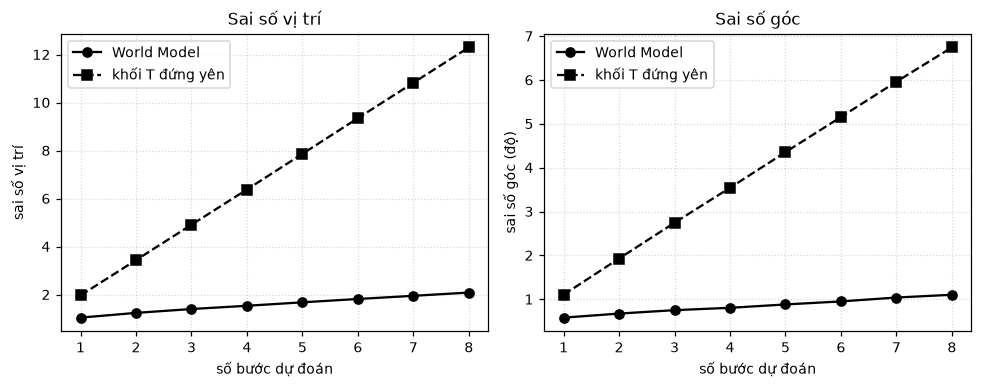

In [22]:
# World Model vòng 1: huấn luyện lại trên dữ liệu người + dữ liệu robot tự chơi (đây là bước huấn luyện duy nhất của vòng lặp)
FILES1 = ["pusht_lowdim.npz", "rollouts_iter1.npz"]
wm1 = train_wm(FILES1, "_iter1", "wm_iter1")
rep1 = wm_report(FILES1, wm1, "_iter1")

**Nhận xét World Model vòng 1 (lần chạy tham chiếu).**
- Trên **các ván của người** (cùng 22 ván kiểm tra như vòng 0): sai số vị trí 1 bước **1,50** (vòng 0: 1,52). Gần như không đổi, tức là thêm dữ liệu mới **không làm World Model quên** cái đã biết.
- Trên **các ván robot tự chơi**: sai số vị trí khi khối T di chuyển chỉ **1,34** so với **5,40** của mốc đứng yên (tốt hơn khoảng 4 lần).
- Lưu ý khi so với vòng 0: tập kiểm tra vòng 1 gồm cả ván tự chơi nên con số "tất cả" **không so thẳng** được với vòng 0; dòng "chỉ ván của người" mới là phép so công bằng.

In [23]:
RESULTS["Diffusion + WM vòng 1"] = evaluate("diffusion_wm_v1", os.path.join(MOD, "wm_iter1.pt"))
print("=== BẢNG KẾT QUẢ (%d ván, seed %d–%d) ===" % (N_EVAL, SEED_EVAL, SEED_EVAL + N_EVAL - 1))
for k in RESULTS:
    show(k)

diffusion_wm_v1            đã chạy 100 ván trong 235 giây
=== BẢNG KẾT QUẢ (100 ván, seed 4000–4099) ===
Chỉ Diffusion              | thành công  69/100 =  69% (KTC 95%: 59–77%) | phủ TB 0.94 | điểm kiểu bài báo 0.981
Diffusion + WM vòng 0      | thành công  70/100 =  70% (KTC 95%: 60–78%) | phủ TB 0.95 | điểm kiểu bài báo 0.991
Diffusion + WM vòng 1      | thành công  80/100 =  80% (KTC 95%: 71–87%) | phủ TB 0.95 | điểm kiểu bài báo 0.988


In [24]:
# ---- So sánh từng ván và độ chắc chắn của chênh lệch ----
def paired(a_name, b_name, tol=0.02, n_boot=5000):
    ba, sa = RESULTS[a_name]; bb, sb = RESULTS[b_name]
    better, worse = int((bb > ba + tol).sum()), int((bb < ba - tol).sum())
    sc_a, sc_b = np.minimum(ba / 0.95, 1), np.minimum(bb / 0.95, 1)
    r = np.random.default_rng(0)
    boots = [(sc_b - sc_a)[r.integers(0, len(sc_a), len(sc_a))].mean() for _ in range(n_boot)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print("%-24s so với %-22s | tốt hơn/ngang/tệ hơn (độ phủ): %2d/%2d/%2d | thành công %+d ván | chênh điểm bài báo %+.3f (KTC 95%%: %+.3f … %+.3f)" %
          (b_name, a_name, better, len(ba) - better - worse, worse, int(sb.sum() - sa.sum()), sc_b.mean() - sc_a.mean(), lo, hi))

paired("Chỉ Diffusion", "Diffusion + WM vòng 0")
paired("Chỉ Diffusion", "Diffusion + WM vòng 1")
paired("Diffusion + WM vòng 0", "Diffusion + WM vòng 1")

Diffusion + WM vòng 0    so với Chỉ Diffusion          | tốt hơn/ngang/tệ hơn (độ phủ): 16/63/21 | thành công +1 ván | chênh điểm bài báo +0.010 (KTC 95%: -0.005 … +0.034)
Diffusion + WM vòng 1    so với Chỉ Diffusion          | tốt hơn/ngang/tệ hơn (độ phủ): 25/60/15 | thành công +11 ván | chênh điểm bài báo +0.007 (KTC 95%: -0.019 … +0.034)
Diffusion + WM vòng 1    so với Diffusion + WM vòng 0  | tốt hơn/ngang/tệ hơn (độ phủ): 21/65/14 | thành công +10 ván | chênh điểm bài báo -0.004 (KTC 95%: -0.024 … +0.008)


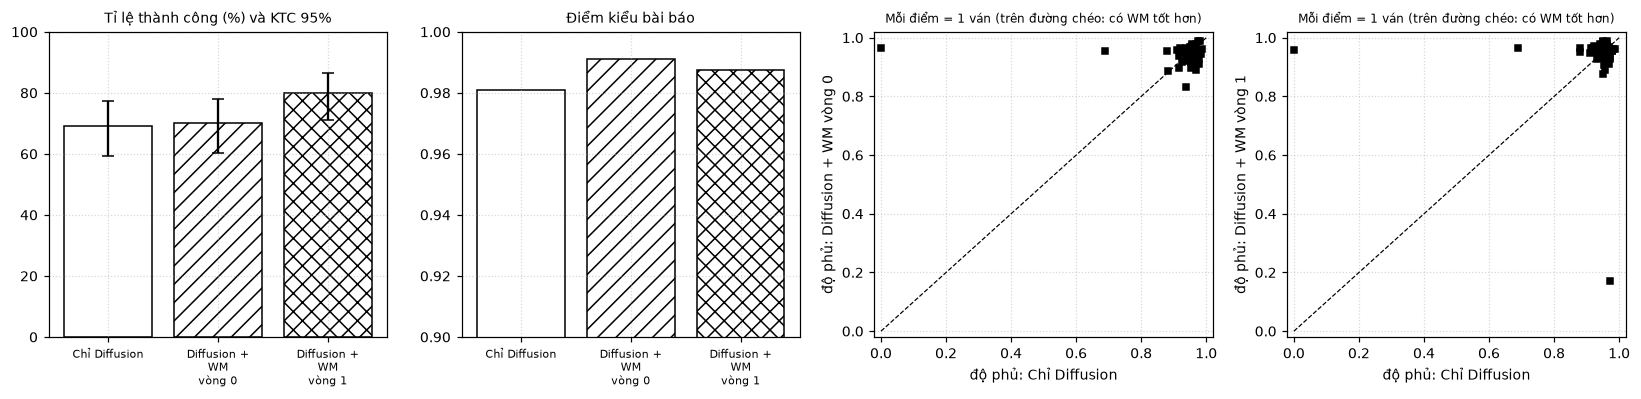

In [25]:
# ---- Hình đen trắng: biểu đồ cột và biểu đồ tán xạ từng ván ----
names = list(RESULTS)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.7))
hatches = ["", "//", "xx"]
for i, k in enumerate(names):
    b, s = RESULTS[k]; lo, hi = wilson(s.sum(), len(s)); p = s.mean()
    axs[0].bar(i, 100 * p, color="white", edgecolor="k", hatch=hatches[i], yerr=[[100 * (p - lo)], [100 * (hi - p)]], capsize=4)
    axs[1].bar(i, paper_score(b), color="white", edgecolor="k", hatch=hatches[i])
for ax, t, yl in ((axs[0], "Tỉ lệ thành công (%) và KTC 95%", (0, 100)), (axs[1], "Điểm kiểu bài báo", (min(0.9, min(paper_score(RESULTS[k][0]) for k in names) - 0.02), 1.0))):
    ax.set_xticks(range(len(names))); ax.set_xticklabels([n.replace(" vòng", "\nvòng").replace("Diffusion + ", "Diffusion +\n") for n in names], fontsize=7)
    ax.set_title(t, fontsize=9); ax.set_ylim(*yl)
ref = RESULTS["Chỉ Diffusion"][0]
for ax, k in ((axs[2], "Diffusion + WM vòng 0"), (axs[3], "Diffusion + WM vòng 1")):
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.plot(ref, RESULTS[k][0], "ks", ms=4)
    ax.set_xlabel("độ phủ: Chỉ Diffusion"); ax.set_ylabel("độ phủ: " + k); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_title("Mỗi điểm = 1 ván (trên đường chéo: có WM tốt hơn)", fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(RES, "b5_ketqua.png"), dpi=150); plt.show()

**Kết quả tham chiếu từ lần chạy của tác giả** (con số có thể lệch vài ván nếu chạy lại, do tính ngẫu nhiên của GPU):

| 100 ván, seed 4000–4099 | Thành công | Phủ TB | Điểm kiểu bài báo |
|---|---|---|---|
| Chỉ Diffusion | 69% | 0,94 | 0,981 |
| Diffusion + WM vòng 0 | 70% | 0,95 | 0,991 |
| Diffusion + WM vòng 1 | **80%** | 0,95 | 0,988 |

Lần đo trước đó trên 50 ván (seed 3000–3049) cho kết quả cùng chiều: 68% → 64% → 70%. Gộp 150 ván: Chỉ Diffusion 69%, WM vòng 0 68%, **WM vòng 1 77%**.

**Nhận xét Bước 5.**
- **Diffusion tự nó đã mạnh:** điểm kiểu bài báo 0,98 (bài báo gốc báo khoảng 0,91–0,95 cho Push-T dạng trạng thái). Vì vậy World Model chỉ còn "dư địa" nhỏ để cải thiện.
- **World Model vòng 0 gần như không thay đổi tỉ lệ thành công** (khoảng 68–70%). Khi nhìn từng ván, số ván tốt hơn và tệ hơn gần cân bằng. Lợi ích chính của nó là **cứu vài ván Diffusion bị kẹt** (các điểm lẻ ở góc trên bên trái biểu đồ tán xạ: ván mà Chỉ Diffusion phủ gần 0, còn có WM phủ trên 0,9). Với các ván bình thường, hai cách chơi gần giống nhau.
- **Vòng lặp có tác dụng:** sau khi World Model học thêm từ ván robot tự chơi, tỉ lệ thành công lên **77–80%** so với 68–70%, ở cả hai lần đo độc lập (50 ván và 100 ván).
- **Mức độ chắc chắn:** chênh khoảng 10 điểm phần trăm trên 100 ván là khá rõ nhưng khoảng tin cậy vẫn rộng (xem bảng và ô so sánh từng ván ở trên). Nên diễn đạt là "cho thấy xu hướng cải thiện", không phải "chứng minh". Muốn kết luận chắc hơn cần nhiều ván hơn (vài trăm).
- **Điểm kiểu bài báo** của hai bản có World Model đều cao hơn Chỉ Diffusion (0,988–0,991 so với 0,981) nhưng chênh nhỏ; vòng 0 và vòng 1 ngang nhau ở chỉ số này. Cải thiện của vòng 1 nằm ở **số ván vượt ngưỡng 0,95**, không phải ở độ phủ trung bình.

### 5.4 Clip minh họa

Mỗi clip gồm **hai khung cạnh nhau, cùng một ván xuất phát** (cùng seed): trái là **Chỉ Diffusion**, phải là **Diffusion + World Model vòng 1**. Mỗi khung ghi số bước và độ phủ hiện tại. Khối T xám cần được đẩy vào hình chữ T đích; ván kết thúc khi độ phủ vượt 95% hoặc hết 300 bước.

Ô dưới tự chọn các ván **Chỉ Diffusion thất bại mà có World Model vòng 1 thành công** (ván dễ thấy tác dụng nhất), cộng thêm một ván đầu tiên để có ví dụ bình thường. Clip được lưu thành file `.gif` trong thư mục `results` và nhúng thẳng vào notebook (cũng như vào bản HTML xuất ra).

Các seed được quay: [4036, 4093, 4000]
seed 4036 | Chỉ Diffusion: phủ 0.00 chưa đạt | Diffusion + WM vòng 1: phủ 0.96 THÀNH CÔNG | 170 khung | 0.4 MB
Clip seed 4036 (trái: Chỉ Diffusion | phải: Diffusion + WM vòng 1):


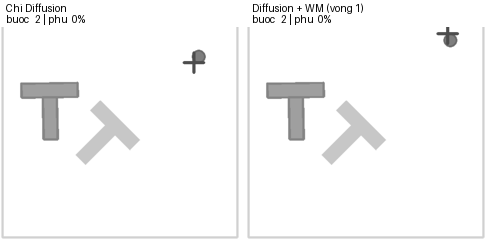

seed 4093 | Chỉ Diffusion: phủ 0.69 chưa đạt | Diffusion + WM vòng 1: phủ 0.96 THÀNH CÔNG | 170 khung | 0.4 MB
Clip seed 4093 (trái: Chỉ Diffusion | phải: Diffusion + WM vòng 1):


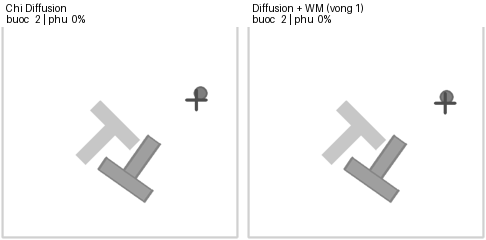

seed 4000 | Chỉ Diffusion: phủ 0.98 THÀNH CÔNG | Diffusion + WM vòng 1: phủ 0.96 THÀNH CÔNG | 112 khung | 0.3 MB
Clip seed 4000 (trái: Chỉ Diffusion | phải: Diffusion + WM vòng 1):


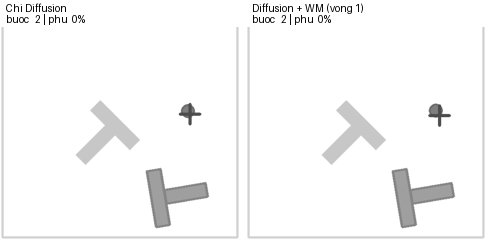

In [26]:
from PIL import Image, ImageDraw
from IPython.display import Image as IPImage, display

CLIP_SIZE, CLIP_STRIDE = 240, 2                      # cạnh mỗi khung (pixel) và lấy 1 khung trên mỗi CLIP_STRIDE bước

def record_clip(seed, model, planner, n_cand, title):
    env_r = make_env(render=True)
    frames = []
    def on_step(step, cov):
        if step % CLIP_STRIDE == 0:
            im = Image.fromarray(env_r.render()).resize((CLIP_SIZE, CLIP_SIZE)).convert("L")
            dr = ImageDraw.Draw(im)
            dr.rectangle([0, 0, CLIP_SIZE, 26], fill=255)
            dr.text((6, 2), title, fill=0)                                   # chữ không dấu vì phông mặc định của PIL không có dấu tiếng Việt
            dr.text((6, 13), "buoc %3d | phu %2d%%" % (step, round(100 * cov)), fill=0)
            frames.append(im)
    best, ok = play(seed, model, env_r, n_cand=n_cand, planner=planner, on_step=on_step)
    env_r.close()
    return frames, best, ok

def make_clip(seed, planner1):
    path = os.path.join(RES, "clip_seed%d.gif" % seed)
    if need(path, "clip"):
        fa, ca, sa = record_clip(seed, dp_final, None, 1, "Chi Diffusion")
        fb, cb, sb = record_clip(seed, dp_final, planner1, K, "Diffusion + WM (vong 1)")
        n = max(len(fa), len(fb))
        fa += [fa[-1]] * (n - len(fa)); fb += [fb[-1]] * (n - len(fb))      # ván nào kết thúc trước thì giữ hình cuối
        out = []
        for x, y in zip(fa, fb):
            im = Image.new("L", (2 * CLIP_SIZE + 6, CLIP_SIZE), 255)
            im.paste(x, (0, 0)); im.paste(y, (CLIP_SIZE + 6, 0)); out.append(im)
        out += [out[-1]] * 20                                              # dừng ở hình cuối 1-2 giây
        out[0].save(path, save_all=True, append_images=out[1:], duration=90, loop=0, optimize=True)
        print("seed %d | Chỉ Diffusion: phủ %.2f %s | Diffusion + WM vòng 1: phủ %.2f %s | %d khung | %.1f MB" %
              (seed, ca, "THÀNH CÔNG" if sa else "chưa đạt", cb, "THÀNH CÔNG" if sb else "chưa đạt", len(out), os.path.getsize(path) / 1e6))
    return path

b_plain, s_plain = RESULTS["Chỉ Diffusion"]; b_v1, s_v1 = RESULTS["Diffusion + WM vòng 1"]
rescued = [i for i in np.argsort(-(b_v1 - b_plain)) if (not s_plain[i]) and s_v1[i]][:2]          # ván WM cứu được, chênh nhiều nhất trước
clip_seeds = [SEED_EVAL + int(i) for i in rescued] + [SEED_EVAL]
clip_seeds = list(dict.fromkeys(clip_seeds))
print("Các seed được quay:", clip_seeds)
planner1 = make_planner(load_wm(os.path.join(MOD, "wm_iter1.pt")))
for sd in clip_seeds:
    p = make_clip(sd, planner1)
    print("Clip seed %d (trái: Chỉ Diffusion | phải: Diffusion + WM vòng 1):" % sd)
    display(IPImage(filename=p))

## 6. Kết luận, hạn chế và câu hỏi còn mở

### 6.1 Bảng tổng hợp (tính trực tiếp từ kết quả vừa chạy)

In [27]:
print("%-26s | %-12s | %-8s | %s" % ("Cấu hình", "Thành công", "Phủ TB", "Điểm kiểu bài báo"))
for k in RESULTS:
    b, s = RESULTS[k]
    print("%-26s | %3d/%d = %3.0f%% | %.2f     | %.3f" % (k, s.sum(), len(s), 100 * s.mean(), b.mean(), paper_score(b)))
print()
print("World Model vòng 0, đoán xa 8 bước (vị trí / góc):  WM %.1f / %.1f°   mốc đứng yên %.1f / %.1f°" % (rep0["r_pos"][-1], rep0["r_ang"][-1], rep0["b_pos"][-1], rep0["b_ang"][-1]))

Cấu hình                   | Thành công   | Phủ TB   | Điểm kiểu bài báo
Chỉ Diffusion              |  69/100 =  69% | 0.94     | 0.981
Diffusion + WM vòng 0      |  70/100 =  70% | 0.95     | 0.991
Diffusion + WM vòng 1      |  80/100 =  80% | 0.95     | 0.988

World Model vòng 0, đoán xa 8 bước (vị trí / góc):  WM 2.8 / 1.5°   mốc đứng yên 13.4 / 7.7°


### 6.2 Những gì đã làm được

1. **Tư thế khối T từ ảnh.** Bộ `lerobot/pusht` không có tư thế khối T; ta ước lượng từ ảnh 96×96 bằng khớp khuôn chữ T (IoU), kiểm tra trên simulator (có đáp án thật) và, nếu có mạng, trên bộ `pusht_keypoints`.
2. **World Model** (MLP nhỏ, 14 số vào, 3 số ra) dự đoán khối T dịch chuyển bao nhiêu; thắng mốc "đứng yên" rõ rệt, và **sai số tăng chậm** khi đoán nối tiếp 8 bước (2,8 so với 13,4).
3. **Diffusion Policy (DiT)** theo cấu hình Bảng 8 của bài báo gốc, chọn checkpoint bằng simulator; đạt điểm kiểu bài báo khoảng 0,98 (bài báo: 0,91–0,95), thành công khoảng 70% theo ngưỡng phủ 95%.
4. **Ghép World Model với Diffusion** bằng cách chọn trong 16 ứng viên; **vòng lặp** (thu dữ liệu robot tự chơi, huấn luyện lại World Model) nâng tỉ lệ thành công từ khoảng 69% lên 77–80%.

### 6.3 Hạn chế (cần nói thẳng)

- **Tư thế khối T là ước lượng**, không phải giá trị gốc. Sai số nhỏ nhưng không bằng không.
- **Mức cải thiện của World Model chưa chắc chắn tuyệt đối:** chênh lệch dựa trên 100–150 ván; khoảng tin cậy còn rộng. Lợi ích của vòng 0 chủ yếu là cứu vài ván bị kẹt.
- **Diffusion đã mạnh sẵn**, nên dư địa cho World Model hẹp. Với một policy yếu hơn, lợi ích có thể lớn hơn (chưa đo).
- **Hệ số robot bám hành động α** được coi là hằng số (0,40); thực tế robot có quán tính và va chạm.
- **Chỉ làm một vòng lặp.** Chưa kiểm tra vòng thứ hai, cũng chưa so sánh bộ lấy mẫu DDIM 16 bước với DDPM 100 bước đầy đủ (bài báo dùng 100 bước trong simulator).
- Mạng DiT của ta là bản tự viết, không phải mã gốc của tác giả; con số so với bài báo mang tính tham khảo.

### 6.4 Câu hỏi còn mở, cần xác nhận với thầy

1. **World Model nối với Diffusion thế nào?** Bài làm chọn "Diffusion sinh K ứng viên, World Model chấm điểm, chọn tốt nhất". Có đúng ý của thầy không, hay thầy muốn World Model nằm ở chỗ khác (ví dụ làm tín hiệu huấn luyện cho Diffusion)?
2. **Số vòng lặp** từ Evaluate về Train WM: bài làm dùng 1 vòng; có cần nhiều hơn không?
3. **Ước lượng tư thế từ ảnh** có được chấp nhận không, hay phải dùng bộ dữ liệu gốc có sẵn tư thế khối T?

### 6.5 Tái lập kết quả

Thư mục `PushT` sau khi chạy gồm: `data\raw` (dữ liệu tải về), `data\sim` (tư thế khối T, `pusht_lowdim.npz`, `rollouts_iter1.npz`), `models` (World Model `wm.pt`, `wm_iter1.pt`; Diffusion `dp_v2_eXXX.pt` và `dp_final.pt`), `results` (hình, clip, kết quả đánh giá `.json`). Thứ tự chạy: **Run All** từ trên xuống. Ô xuất HTML ngay dưới (tùy chọn).

In [28]:
# (Tùy chọn) Xuất bản HTML của chính notebook này: bỏ dấu # ở dòng dưới. Đổi tên file cho đúng với tên notebook đang lưu.
# !jupyter nbconvert --to html PushT_WorldModel.ipynb